# Treino — SpacialCNN — cross-validation por região

Notebook limpo para avaliar a CNN com **5-fold cross-validation dentro de cada região**.

Lógica usada:
- cada região é avaliada separadamente;
- em cada região, os pontos são divididos em 5 folds;
- a divisão é estratificada por classes de altura;
- a normalização é calculada apenas com o treino de cada fold;
- as métricas finais são a média e o desvio padrão dos 5 folds por região.


In [1]:
# ============================================================
# 1. IMPORTS E CONFIGURAÇÃO GLOBAL
# ============================================================

import time
import json
import re
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import rasterio
import geopandas as gpd

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from IPython.display import display

# -----------------------------
# Caminhos
# -----------------------------
RAW_BASE_DIR = Path(r"D:\Tese_data_refinada\_example_patches")
VALIDATION_DIR = Path(r"D:\Tese_data_refinada\Areas_gpkg")
OUTPUT_DIR = Path("outputs_fch/spacial_cnn/cv_por_regiao_estratificado")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# -----------------------------
# Experiência
# -----------------------------
SEED = 42
TARGET_COLUMN = "rh_opt_098"
TARGET_SCALE = 100.0  # cm → metros

# -----------------------------
# Cross-validation
# -----------------------------
N_SPLITS = 5
N_HEIGHT_BINS = 5

# -----------------------------
# Hiperparâmetros
# -----------------------------
BATCH_SIZE = 64
LR = 3e-4
WEIGHT_DECAY = 0.0
EPOCHS = 40
PATIENCE = 15
LOG_EVERY = 5

# -----------------------------
# Hardware
# -----------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {device}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM disponível: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")


def set_seed(seed=42):
    """Garante reprodutibilidade tanto quanto possível."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)


Dispositivo: cuda
GPU: NVIDIA GeForce RTX 3060
VRAM disponível: 12.9 GB


In [2]:
# ============================================================
# 2. DATASET E AUGMENTATION
# ============================================================

class FCHDataset(Dataset):
    def __init__(self, X, y, transform=None):
        self.X = X.astype(np.float32)
        self.y = y.astype(np.float32)
        self.transform = transform

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        x = self.X[idx].copy()
        if self.transform is not None:
            x = self.transform(x)
        return (torch.tensor(x, dtype=torch.float32),
                torch.tensor(self.y[idx], dtype=torch.float32))


def base_augmentation(x):
    """Rotações e flips aleatórios (apenas treino)."""
    k = np.random.randint(0, 4)
    if k > 0:
        x = np.rot90(x, k, axes=(1, 2)).copy()
    if np.random.rand() > 0.5:
        x = np.flip(x, axis=2).copy()
    if np.random.rand() > 0.5:
        x = np.flip(x, axis=1).copy()
    return x

In [3]:
# ============================================================
# 3. CARREGAMENTO DOS TIFs
# ============================================================

def extract_point_id(filename):
    """Extrai o ID do ponto a partir do nome do ficheiro TIF."""
    match = re.search(r"point_(\d+)_", filename)
    if match is None:
        raise ValueError(f"Não consegui extrair point_id de: {filename}")
    return int(match.group(1))


def build_target_dict(gdf, target_column):
    """Cria dicionário point_id → target."""
    possible_id_cols = ["point_id", "POINT_ID", "id", "ID", "fid", "FID"]
    id_col = next((col for col in possible_id_cols if col in gdf.columns), None)

    if id_col is None:
        print("   Aviso: sem coluna explícita de ID. A usar gdf.index como ID dos pontos.")
        ids = gdf.index.astype(int).values
    else:
        ids = gdf[id_col].astype(int).values

    targets = gdf[target_column].values
    return {
        int(pid): float(target)
        for pid, target in zip(ids, targets)
        if not pd.isna(target)
    }


def get_valid_band_indices(metadata_path):
    """
    Lê o metadata e remove bandas com potencial leakage.

    A lógica remove bandas cujo nome contenha CHM, LIDAR ou OTHER.
    """
    with open(metadata_path, "r", encoding="utf-8") as file:
        metadata = json.load(file)

    raster_names = metadata.get("raster_names", [])

    leakage_terms = ("CHM", "LIDAR", "OTHER")
    valid_indices = [
        i
        for i, name in enumerate(raster_names)
        if not any(term in name.upper() for term in leakage_terms)
    ]

    removed = [
        name
        for name in raster_names
        if any(term in name.upper() for term in leakage_terms)
    ]

    if removed:
        print(f"   Bandas removidas por possível leakage: {removed}")

    return valid_indices, raster_names


def load_all_regions_tifs(raw_base_dir, validation_dir, target_column="rh_opt_098"):
    """Carrega todos os patches TIF e associa cada patch ao target do respetivo GeoPackage."""
    raw_base_dir = Path(raw_base_dir)
    validation_dir = Path(validation_dir)

    X_list = []
    y_list = []
    region_list = []
    point_id_list = []
    channels_ref = None

    print("-> A ler TIFs e cruzar com GeoPackages...")

    for area_dir in sorted(raw_base_dir.iterdir()):
        if not area_dir.is_dir():
            continue

        area_name = area_dir.name
        gpkg_path = validation_dir / f"{area_name}_HEIGHT_Dataset.gpkg"
        metadata_files = list(area_dir.glob("*.json"))

        if not gpkg_path.exists():
            print(f"   [{area_name}] GeoPackage não encontrado — ignorado.")
            continue

        if not metadata_files:
            print(f"   [{area_name}] metadata JSON não encontrado — ignorado.")
            continue

        print(f"\nÁrea: {area_name}")

        gdf = gpd.read_file(gpkg_path)
        target_dict = build_target_dict(gdf, target_column)
        valid_indices, _ = get_valid_band_indices(metadata_files[0])

        if channels_ref is None:
            channels_ref = len(valid_indices)
        elif len(valid_indices) != channels_ref:
            raise ValueError(
                f"Canais incompatíveis em {area_name}: "
                f"esperado {channels_ref}, obtido {len(valid_indices)}"
            )

        n_loaded = 0
        n_no_target = 0

        for tif_path in sorted(area_dir.rglob("*.tif")):
            point_id = extract_point_id(tif_path.name)

            if point_id not in target_dict:
                n_no_target += 1
                continue

            with rasterio.open(tif_path) as src:
                patch = src.read().astype(np.float32)[valid_indices]

            X_list.append(patch)
            y_list.append(target_dict[point_id])
            region_list.append(area_name)
            point_id_list.append(point_id)
            n_loaded += 1

        print(f"   Patches carregados: {n_loaded} | Sem target: {n_no_target}")

    if not X_list:
        raise RuntimeError("Nenhum patch carregado.")

    X = np.stack(X_list).astype(np.float32)
    y = np.array(y_list, dtype=np.float32)
    regions = np.array(region_list)
    point_ids = np.array(point_id_list)

    print(f"\nResumo: X={X.shape} | y={y.shape} | regiões={sorted(set(regions))}")
    print(f"NaNs em X: {np.isnan(X).mean() * 100:.4f}%")

    return X, y, regions, point_ids


In [4]:
# ============================================================
# 4. NORMALIZAÇÃO SEM LEAKAGE
# ============================================================

def normalize_from_train(X_train_raw, X_val_raw):
    mean = np.nanmean(X_train_raw, axis=(0, 2, 3), keepdims=True)
    std  = np.nanstd(X_train_raw,  axis=(0, 2, 3), keepdims=True)
    std  = np.where(std == 0, 1e-6, std)

    X_train = np.nan_to_num((X_train_raw - mean) / std, nan=0., posinf=0., neginf=0.).astype(np.float32)
    X_val   = np.nan_to_num((X_val_raw   - mean) / std, nan=0., posinf=0., neginf=0.).astype(np.float32)

    print(f"Normalização concluída | média_treino≈{np.mean(X_train):.5f} | std_treino≈{np.std(X_train):.5f}")
    return X_train, X_val, mean, std

In [5]:
# ============================================================
# 5. ARQUITETURA 
# ============================================================

class SpacialCNN(nn.Module):
    """
    CNN leve com dilated convolution para patches 15×15 multi-sensor.
    in_channels = n_bandas + n_sensores (máscaras de disponibilidade)
    """
    def __init__(self, in_channels: int):
        super().__init__()

        self.encoder = nn.Sequential(
            # Bloco 1 — extracção local, 15×15 → 15×15
            nn.Conv2d(in_channels, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.GELU(),

            # Bloco 2 — 15×15 → 15×15
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.GELU(),

            # Bloco 3 dilated — campo recetor 9×9 sem reduzir resolução
            nn.Conv2d(128, 128, kernel_size=3, padding=2, dilation=2, bias=False),
            nn.BatchNorm2d(128),
            nn.GELU(),

            # Bloco 4 — 15×15 → 15×15
            nn.Conv2d(128, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.GELU(),
        )

        # Reduz para 3×3 antes do MLP (evita flatten de 15×15×256 = 57 600 neurónios)
        self.pool = nn.AdaptiveAvgPool2d((3, 3))

        self.regressor = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 3 * 3, 256, bias=False),
            nn.BatchNorm1d(256),
            nn.GELU(),
            nn.Dropout(0.3),

            nn.Linear(256, 64),
            nn.GELU(),
            nn.Dropout(0.2),

            nn.Linear(64, 1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.encoder(x)
        x = self.pool(x)
        return self.regressor(x).squeeze(1)


def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Parâmetros totais: {total:,} | treináveis: {trainable:,}")
    return total, trainable

In [6]:
# ============================================================
# 6. FUNÇÕES DE MÉTRICAS E TREINO
# ============================================================

def regression_metrics(y_true, y_pred):
    y_true_np = np.array(y_true).flatten()
    y_pred_np = np.array(y_pred).flatten()

    rmse = np.sqrt(mean_squared_error(y_true_np, y_pred_np))
    mae = mean_absolute_error(y_true_np, y_pred_np)
    r2 = r2_score(y_true_np, y_pred_np)
    bias = np.mean(y_pred_np - y_true_np)
    covariancia = np.cov(y_true_np, y_pred_np)[0, 1]
    
    # Cálculo do %RMSE (RMSE / média real * 100)
    y_true_mean = np.mean(y_true_np)
    pct_rmse = (rmse / y_true_mean) * 100 if y_true_mean > 0 else float("nan")
    
    return {
        "RMSE": rmse,
        "%RMSE": pct_rmse, 
        "MAE": mae,
        "R2": r2,
        "Bias": bias,
        "Covariancia": covariancia 
    }


def _eval_loader(model, loader):
    """Devolve (y_true, y_pred) em numpy para um loader completo."""
    model.eval()
    all_preds, all_targets = [], []
    with torch.no_grad():
        for bX, by in loader:
            all_preds.append(model(bX.to(device)).cpu().numpy())
            all_targets.append(by.numpy())
    return np.concatenate(all_targets), np.concatenate(all_preds)


def train_spacialcnn_cnn(
    model, train_loader, val_loader, model_name,
    epochs=40, patience=15, lr=3e-4, weight_decay=0.0, log_every=5,
):
    """
    Treina a SpacialCNN com early stopping.

    Imprime a cada época (ou quando há melhoria):
      - MSE treino/val
      - RMSE val (metros)
      - %RMSE val  ← RMSE relativo à média de y_true na validação
      - MAE val
      - R² val
      - learning rate atual
      - tempo da época
      - ETA estimado
    """
    model = model.to(device)
    criterion  = nn.MSELoss()
    optimizer  = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler  = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=5)
    ckpt_path  = OUTPUT_DIR / f"ckpt_{model_name}.pth"

    best_val_loss   = np.inf
    best_epoch      = 0
    epochs_no_impr  = 0
    history = {"epoch": [], "train_mse": [], "val_mse": [],
               "val_rmse": [], "val_pct_rmse": [], "val_mae": [], "val_r2": [], "lr": []}

    # Pré-calcular média de y_val para o %RMSE
    y_val_all = np.concatenate([by.numpy() for _, by in val_loader])
    y_val_mean = float(np.mean(y_val_all))

    header = (f"{'Época':>6}  {'MSE_tr':>8}  {'MSE_val':>8}  "
              f"{'RMSE_val':>9}  {'%RMSE':>6}  {'MAE':>7}  {'R²':>6}  "
              f"{'LR':>9}  {'s/ep':>5}  {'ETA':>6}")
    print(f"\n{'─'*len(header)}")
    print(header)
    print(f"{'─'*len(header)}")

    epoch_times = []

    for epoch in range(1, epochs + 1):
        t0 = time.time()

        # --- Treino ---
        model.train()
        train_loss_sum = 0.0
        for bX, by in train_loader:
            bX, by = bX.to(device), by.to(device)
            optimizer.zero_grad()
            loss = criterion(model(bX), by)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * bX.size(0)
        train_mse = train_loss_sum / len(train_loader.dataset)

        # --- Validação (com métricas completas) ---
        y_true_v, y_pred_v = _eval_loader(model, val_loader)
        val_mse     = float(mean_squared_error(y_true_v, y_pred_v))
        val_rmse    = float(np.sqrt(val_mse))
        val_pct_rmse = (val_rmse / y_val_mean) * 100 if y_val_mean > 0 else float("nan")
        val_mae     = float(mean_absolute_error(y_true_v, y_pred_v))
        val_r2      = float(r2_score(y_true_v, y_pred_v))

        scheduler.step(val_mse)
        current_lr = optimizer.param_groups[0]["lr"]

        elapsed = time.time() - t0
        epoch_times.append(elapsed)
        remaining_epochs = epochs - epoch
        avg_ep_time = np.mean(epoch_times[-10:])   # média das últimas 10 épocas
        eta_s = remaining_epochs * avg_ep_time
        eta_str = f"{int(eta_s//60)}m{int(eta_s%60):02d}s" if eta_s >= 60 else f"{eta_s:.0f}s"

        improved = val_mse < best_val_loss
        if improved:
            best_val_loss  = val_mse
            best_epoch     = epoch
            epochs_no_impr = 0
            torch.save(model.state_dict(), ckpt_path)
            flag = " ⭐"
        else:
            epochs_no_impr += 1
            flag = ""

        history["epoch"].append(epoch)
        history["train_mse"].append(train_mse)
        history["val_mse"].append(val_mse)
        history["val_rmse"].append(val_rmse)
        history["val_pct_rmse"].append(val_pct_rmse)
        history["val_mae"].append(val_mae)
        history["val_r2"].append(val_r2)
        history["lr"].append(current_lr)

        if epoch == 1 or epoch % log_every == 0 or improved:
            print(
                f"{epoch:>6}  {train_mse:>8.4f}  {val_mse:>8.4f}  "
                f"{val_rmse:>8.3f}m  {val_pct_rmse:>5.1f}%  {val_mae:>6.3f}m  {val_r2:>6.3f}  "
                f"{current_lr:>9.2e}  {elapsed:>4.1f}s  {eta_str:>6}{flag}"
            )

        if epochs_no_impr >= patience:
            print(f"\nEarly stopping na época {epoch} (sem melhoria há {patience} épocas).")
            break

    print(f"{'─'*len(header)}")
    print(f"Melhor época: {best_epoch} | Melhor val MSE: {best_val_loss:.4f} | RMSE: {np.sqrt(best_val_loss):.3f}m")
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    return model, pd.DataFrame(history)


def evaluate_model(model, val_loader, model_name):
    rows, preds_dict = [], {}
    # Avaliar apenas a validação
    for split_name, loader in [("val", val_loader)]:
        y_true, y_pred = _eval_loader(model, loader)
        m = regression_metrics(y_true, y_pred)
        rows.append({"model": model_name, "split": split_name, **m})
        preds_dict[split_name] = {"y_true": y_true, "y_pred": y_pred}
    return pd.DataFrame(rows), preds_dict

In [7]:
# ============================================================
# 7. GRÁFICOS
# ============================================================

def save_fig(path):
    """Guarda e mostra a figura atual."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Figura: {path}")


def plot_learning_curves(history, model_name, region):
    """Mostra curvas de treino e validação para um fold."""
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].plot(history["epoch"], history["train_mse"], label="treino")
    axes[0].plot(history["epoch"], history["val_mse"], label="validação", linestyle="--")
    axes[0].set(title="MSE", xlabel="Época", ylabel="MSE")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(history["epoch"], history["val_rmse"], label="RMSE (m)")
    axes[1].plot(history["epoch"], history["val_mae"], label="MAE (m)", linestyle="--")
    axes[1].set(title="RMSE e MAE na validação", xlabel="Época", ylabel="m")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    axes[2].plot(history["epoch"], history["val_pct_rmse"], label="%RMSE")
    ax2 = axes[2].twinx()
    ax2.plot(history["epoch"], history["val_r2"], linestyle=":", label="R²")
    axes[2].set(title="%RMSE e R² na validação", xlabel="Época", ylabel="%RMSE")
    ax2.set_ylabel("R²")
    axes[2].legend(loc="upper right")
    ax2.legend(loc="upper center")
    axes[2].grid(alpha=0.3)

    plt.suptitle(f"{model_name} — {region}", fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()


def plot_true_vs_pred(y_true, y_pred, model_name, split_name, region):
    """Gráfico real vs previsto."""
    mn = min(y_true.min(), y_pred.min())
    mx = max(y_true.max(), y_pred.max())
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    plt.figure(figsize=(5, 5))
    plt.scatter(y_true, y_pred, alpha=0.6, s=12)
    plt.plot([mn, mx], [mn, mx], "--k")
    plt.xlabel("Real (m)")
    plt.ylabel("Previsto (m)")
    plt.title(f"{model_name} | {split_name} | {region}\nRMSE={rmse:.3f} m | R²={r2:.3f}")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


def plot_residuals(y_true, y_pred, model_name, split_name, region):
    """Gráfico dos resíduos: previsto - real."""
    residuals = y_pred - y_true

    plt.figure(figsize=(5, 4))
    plt.scatter(y_pred, residuals, alpha=0.6, s=12)
    plt.axhline(0, linestyle="--", color="k")
    plt.xlabel("Previsto (m)")
    plt.ylabel("Resíduo (m)")
    plt.title(f"Resíduos | {model_name} | {split_name} | {region}")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


In [8]:
# ============================================================
# 8. FUNÇÕES AUXILIARES PARA CROSS-VALIDATION ESTRATIFICADA
# ============================================================

def safe_name(text):
    """Converte texto num nome seguro para ficheiros/checkpoints."""
    return re.sub(r"[^A-Za-z0-9_-]+", "_", str(text))


def make_height_classes(y, n_bins=5):
    """
    Cria classes de altura por quantis.

    Com n_bins=5:
      - classe 0: alturas mais baixas;
      - classe 4: alturas mais altas.

    Como é feito por quantis, cada classe tenta ficar com número semelhante
    de amostras dentro da região em análise.
    """
    y = np.asarray(y, dtype=float)

    if len(y) == 0:
        raise ValueError("y está vazio.")

    if len(np.unique(y)) < 2 or n_bins <= 1:
        classes = np.zeros(len(y), dtype=int)
        bins = np.array([np.min(y), np.max(y)])
        return classes, bins

    classes, bins = pd.qcut(
        pd.Series(y),
        q=n_bins,
        labels=False,
        duplicates="drop",
        retbins=True,
    )

    return classes.astype(int).to_numpy(), bins


def choose_height_classes_for_cv(y, n_splits=5, max_bins=5, label=""):
    """
    Escolhe classes de altura compatíveis com StratifiedKFold.

    Cada classe precisa de ter pelo menos n_splits amostras. Caso contrário,
    não é possível distribuir essa classe por todos os folds.
    """
    y = np.asarray(y, dtype=float)

    if len(y) < n_splits:
        raise ValueError(
            f"{label} tem apenas {len(y)} amostras. "
            f"Não dá para fazer {n_splits} folds."
        )

    max_bins_possible = min(max_bins, len(np.unique(y)), len(y))

    for n_bins in range(max_bins_possible, 0, -1):
        height_classes, bin_edges = make_height_classes(y, n_bins=n_bins)
        counts = pd.Series(height_classes).value_counts()

        if counts.min() >= n_splits:
            if n_bins < max_bins:
                print(
                    f"AVISO {label}: reduzi as classes de altura de "
                    f"{max_bins} para {n_bins}, porque havia classes "
                    f"com menos de {n_splits} amostras."
                )
            return height_classes, bin_edges

    raise ValueError(
        f"{label}: não foi possível criar classes de altura válidas "
        f"para {n_splits} folds."
    )


def print_height_bins(bin_edges, target_scale=100.0):
    """Mostra os limites das classes de altura em metros."""
    print("\nLimites das classes de altura:")
    for i in range(len(bin_edges) - 1):
        lo = bin_edges[i] / target_scale
        hi = bin_edges[i + 1] / target_scale
        print(f"  Classe {i}: {lo:.2f} m até {hi:.2f} m")


def build_loaders_from_indices(X_all, y_all, train_idx, val_idx):
    """
    Normaliza sem leakage e cria DataLoaders.

    A média e o desvio padrão são calculados só com as amostras de treino
    do fold atual.
    """
    X_train, X_val, _, _ = normalize_from_train(
        X_all[train_idx],
        X_all[val_idx],
    )

    y_train = y_all[train_idx] / TARGET_SCALE
    y_val = y_all[val_idx] / TARGET_SCALE

    print(
        f"\ny_train: média={y_train.mean():.3f} m | std={y_train.std():.3f} m | "
        f"min={y_train.min():.2f} m | max={y_train.max():.2f} m"
    )
    print(
        f"y_val:   média={y_val.mean():.3f} m | std={y_val.std():.3f} m | "
        f"min={y_val.min():.2f} m | max={y_val.max():.2f} m"
    )

    train_dataset = FCHDataset(X_train, y_train, transform=base_augmentation)
    val_dataset = FCHDataset(X_val, y_val)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        drop_last=(len(train_dataset) % BATCH_SIZE == 1),
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
    )

    return train_loader, val_loader


def run_fold(
    X_all,
    y_all,
    regions_all,
    point_ids_all,
    train_idx,
    val_idx,
    model_name,
    fold_label,
    result_extra=None,
):
    """Treina e avalia uma fold de validação."""
    result_extra = result_extra or {}

    print("\n" + "=" * 65)
    print(f" {fold_label}")
    print("=" * 65)
    print(f"Treino: {len(train_idx)} amostras")
    print(f"Validação: {len(val_idx)} amostras")
    print(f"Regiões treino: {sorted(set(regions_all[train_idx]))}")
    print(f"Regiões validação: {sorted(set(regions_all[val_idx]))}")

    set_seed(SEED)

    train_loader, val_loader = build_loaders_from_indices(
        X_all,
        y_all,
        train_idx,
        val_idx,
    )

    model = SpacialCNN(in_channels=X_all.shape[1])

    print("\nArquitetura: SpacialCNN")
    count_parameters(model)

    model, history = train_spacialcnn_cnn(
        model,
        train_loader,
        val_loader,
        model_name=model_name,
        epochs=EPOCHS,
        patience=PATIENCE,
        lr=LR,
        weight_decay=WEIGHT_DECAY,
        log_every=LOG_EVERY,
    )

    results_df, preds = evaluate_model(
        model,
        val_loader,
        model_name="SpacialCNN",
    )

    for key, value in result_extra.items():
        results_df[key] = value

    results_df["n_train"] = len(train_idx)
    results_df["n_val"] = len(val_idx)

    val_row = results_df[results_df["split"] == "val"].iloc[0]
    print(
        f"\n>>> Validação final | RMSE={val_row['RMSE']:.3f} m | "
        f"%RMSE={val_row['%RMSE']:.1f}% | MAE={val_row['MAE']:.3f} m | "
        f"R²={val_row['R2']:.3f}"
    )

    plot_learning_curves(
        history,
        model_name=model_name,
        region=fold_label,
    )

    plot_true_vs_pred(
        preds["val"]["y_true"],
        preds["val"]["y_pred"],
        model_name="SpacialCNN",
        split_name="val",
        region=fold_label,
    )

    plot_residuals(
        preds["val"]["y_true"],
        preds["val"]["y_pred"],
        model_name="SpacialCNN",
        split_name="val",
        region=fold_label,
    )

    return results_df, history


def summarize_final_results(final_df, group_cols):
    """Calcula média e desvio padrão das métricas de validação."""
    metric_cols = ["RMSE", "%RMSE", "MAE", "R2", "Bias", "Covariancia"]

    summary = (
        final_df[final_df["split"] == "val"]
        .groupby(group_cols)[metric_cols]
        .agg(["mean", "std"])
    )

    display(summary)
    return summary


 PIPELINE FCH — SpacialCNN — CV por região
-> A ler TIFs e cruzar com GeoPackages...

Área: Mafra
   Aviso: sem coluna explícita de ID. A usar gdf.index como ID dos pontos.
   Bandas removidas por possível leakage: ['Mafra_20200000_CHM_AGBD_ALL', 'Mafra_20200000_CHM_BGBD_ALL', 'Mafra_20200000_CHM_LBD_ALL', 'Mafra_20200000_CHM_SBD_ALL']
   Patches carregados: 463 | Sem target: 0

Área: Monsanto
   Aviso: sem coluna explícita de ID. A usar gdf.index como ID dos pontos.
   Bandas removidas por possível leakage: ['Monsanto_20200000_CHM_AGBD_ALL', 'Monsanto_20200000_CHM_BGBD_ALL', 'Monsanto_20200000_CHM_LBD_ALL', 'Monsanto_20200000_CHM_SBD_ALL']
   Patches carregados: 455 | Sem target: 0

Área: Pombal
   Aviso: sem coluna explícita de ID. A usar gdf.index como ID dos pontos.
   Bandas removidas por possível leakage: ['Pombal_20200000_CHM_AGBD_ALL', 'Pombal_20200000_CHM_BGBD_ALL', 'Pombal_20200000_CHM_LBD_ALL', 'Pombal_20200000_CHM_SBD_ALL']
   Patches carregados: 850 | Sem target: 0

Área: 

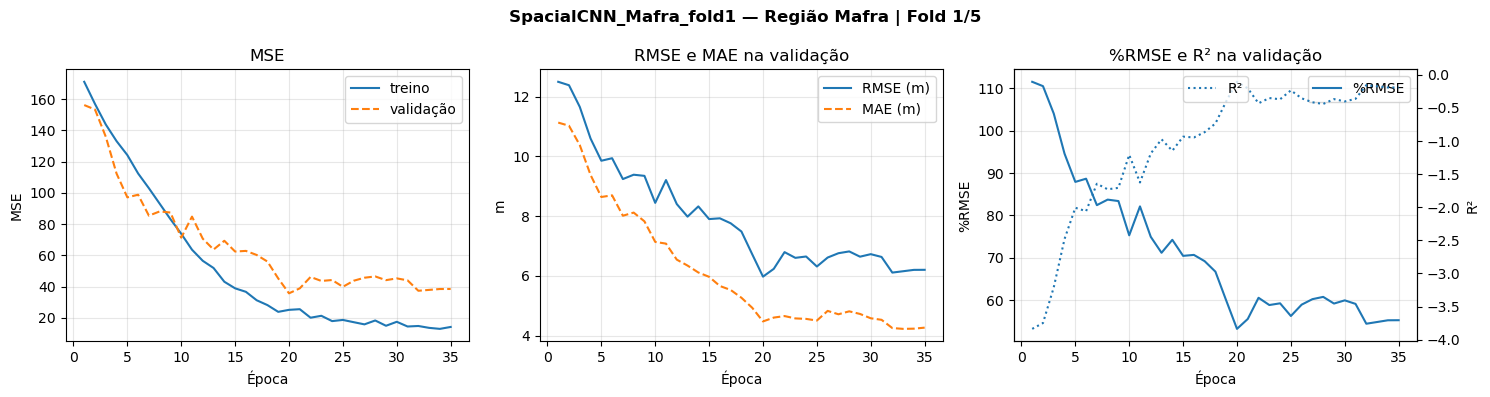

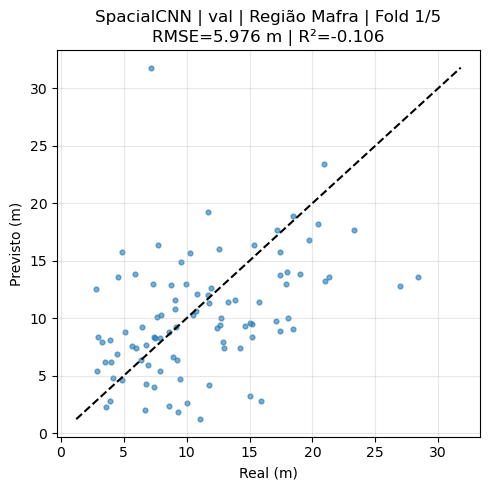

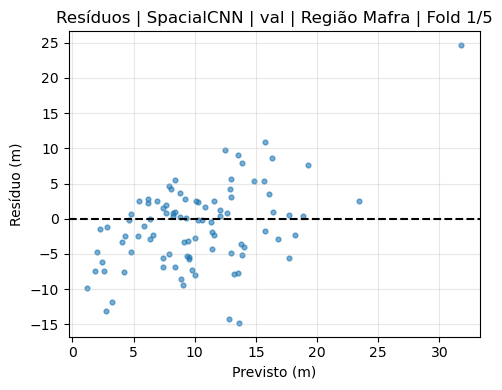


 Região Mafra | Fold 2/5
Treino: 370 amostras
Validação: 93 amostras
Regiões treino: ['Mafra']
Regiões validação: ['Mafra']
Normalização concluída | média_treino≈0.00000 | std_treino≈0.99999

y_train: média=11.681 m | std=5.901 m | min=2.69 m | max=30.96 m
y_val:   média=11.735 m | std=6.186 m | min=2.54 m | max=36.34 m

Arquitetura: SpacialCNN
Parâmetros totais: 1,298,049 | treináveis: 1,298,049

────────────────────────────────────────────────────────────────────────────────────────
 Época    MSE_tr   MSE_val   RMSE_val   %RMSE      MAE      R²         LR   s/ep     ETA
────────────────────────────────────────────────────────────────────────────────────────
     1  166.5201  174.9529    13.227m  112.7%  11.693m  -3.572   3.00e-04   0.2s      9s ⭐
     2  152.9827  173.3754    13.167m  112.2%  11.655m  -3.531   3.00e-04   0.2s      9s ⭐
     3  140.7120  156.7489    12.520m  106.7%  11.110m  -3.096   3.00e-04   0.2s      8s ⭐
     4  130.2395  129.8665    11.396m   97.1%   9.974m  -2

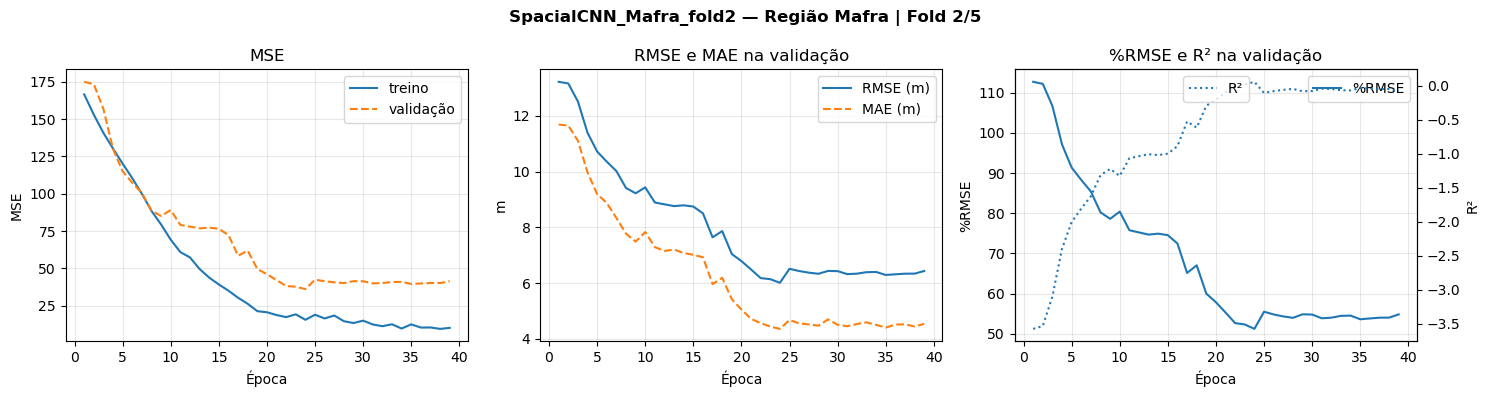

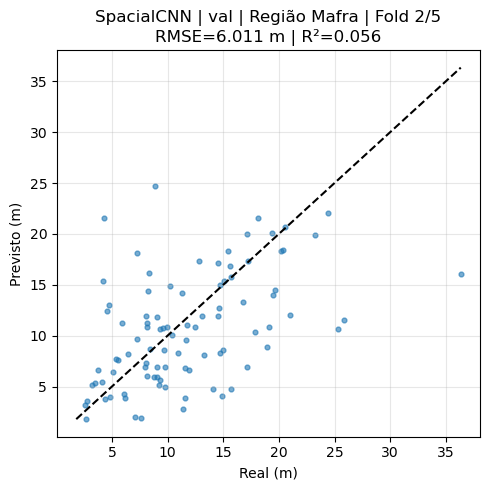

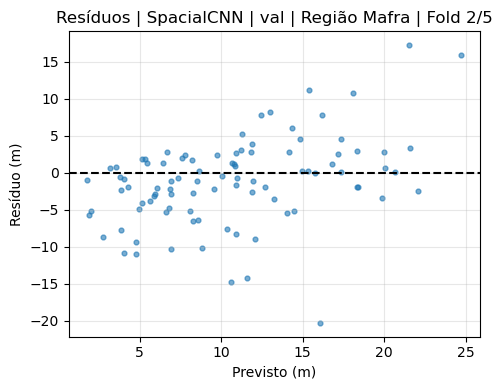


 Região Mafra | Fold 3/5
Treino: 370 amostras
Validação: 93 amostras
Regiões treino: ['Mafra']
Regiões validação: ['Mafra']
Normalização concluída | média_treino≈0.00000 | std_treino≈0.99999

y_train: média=11.623 m | std=5.928 m | min=2.54 m | max=36.34 m
y_val:   média=11.966 m | std=6.076 m | min=2.84 m | max=30.96 m

Arquitetura: SpacialCNN
Parâmetros totais: 1,298,049 | treináveis: 1,298,049

────────────────────────────────────────────────────────────────────────────────────────
 Época    MSE_tr   MSE_val   RMSE_val   %RMSE      MAE      R²         LR   s/ep     ETA
────────────────────────────────────────────────────────────────────────────────────────
     1  165.6151  178.3496    13.355m  111.6%  11.894m  -3.831   3.00e-04   0.2s      9s ⭐
     2  152.2706  174.6452    13.215m  110.4%  11.762m  -3.730   3.00e-04   0.2s      9s ⭐
     3  139.2736  155.1161    12.455m  104.1%  11.053m  -3.201   3.00e-04   0.2s      8s ⭐
     4  129.5883  128.4367    11.333m   94.7%   9.884m  -2

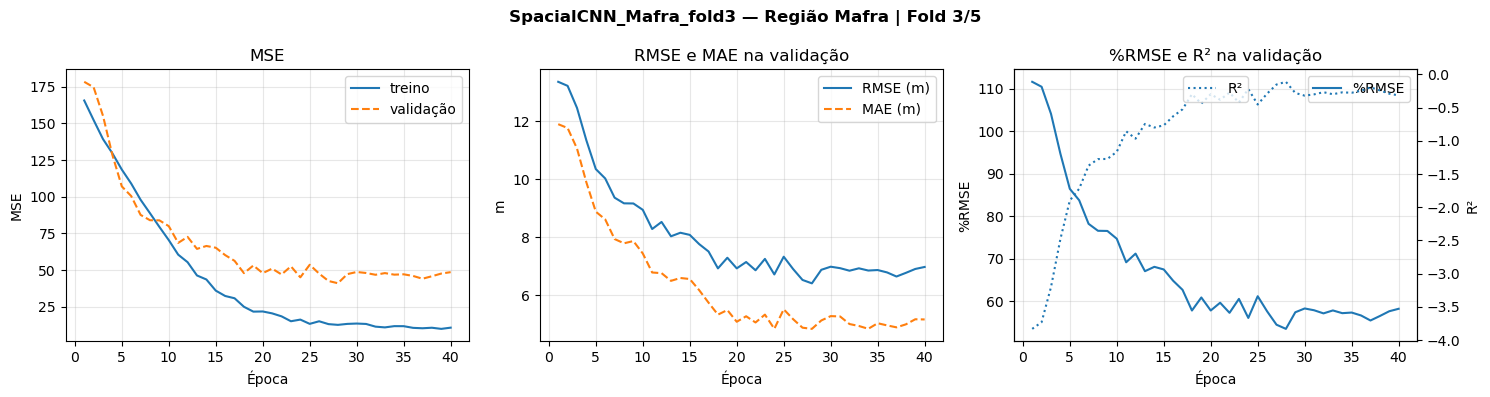

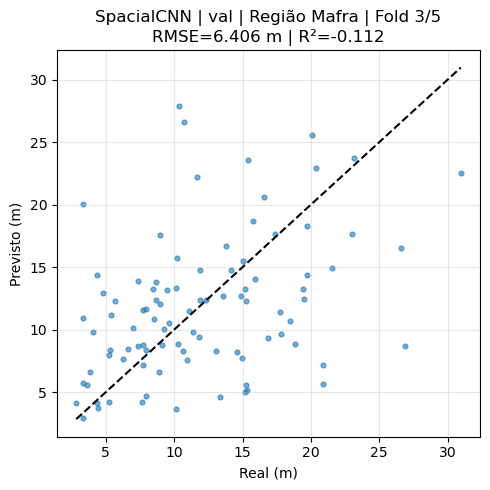

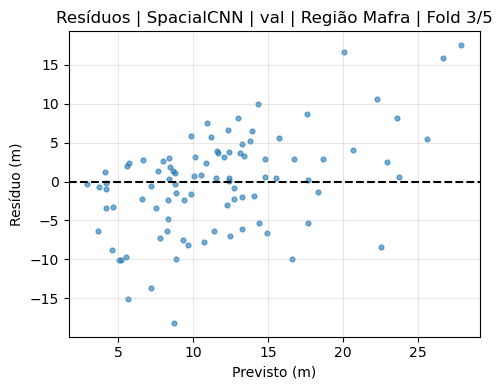


 Região Mafra | Fold 4/5
Treino: 371 amostras
Validação: 92 amostras
Regiões treino: ['Mafra']
Regiões validação: ['Mafra']
Normalização concluída | média_treino≈0.00000 | std_treino≈0.99999

y_train: média=11.694 m | std=6.004 m | min=2.54 m | max=36.34 m
y_val:   média=11.687 m | std=5.778 m | min=2.69 m | max=27.02 m

Arquitetura: SpacialCNN
Parâmetros totais: 1,298,049 | treináveis: 1,298,049

────────────────────────────────────────────────────────────────────────────────────────
 Época    MSE_tr   MSE_val   RMSE_val   %RMSE      MAE      R²         LR   s/ep     ETA
────────────────────────────────────────────────────────────────────────────────────────
     1  168.5610  168.5030    12.981m  111.1%  11.626m  -4.047   3.00e-04   0.3s     10s ⭐
     2  154.7706  164.8354    12.839m  109.9%  11.512m  -3.937   3.00e-04   0.2s     10s ⭐
     3  141.2117  147.5864    12.149m  104.0%  10.932m  -3.420   3.00e-04   0.2s      9s ⭐
     4  131.5705  121.8220    11.037m   94.4%   9.882m  -2

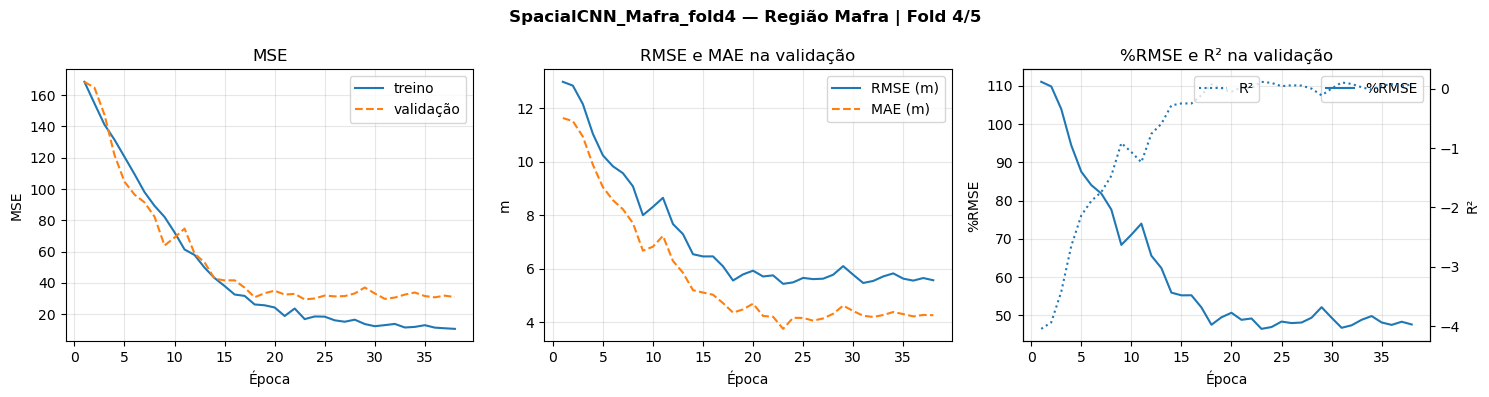

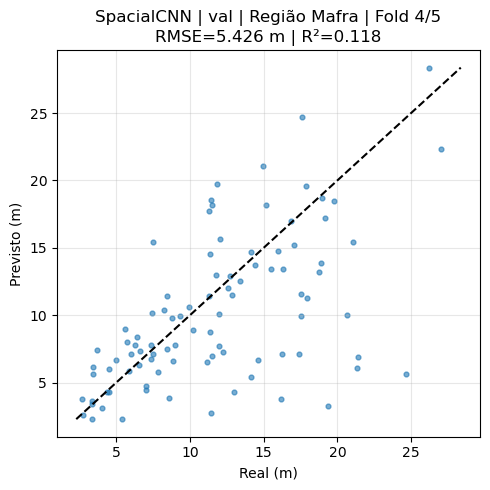

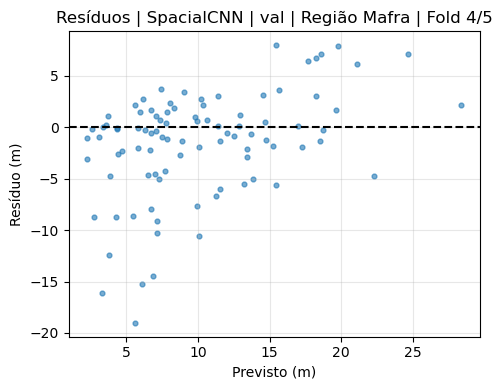


 Região Mafra | Fold 5/5
Treino: 371 amostras
Validação: 92 amostras
Regiões treino: ['Mafra']
Regiões validação: ['Mafra']
Normalização concluída | média_treino≈0.00000 | std_treino≈0.99999

y_train: média=11.650 m | std=5.941 m | min=2.54 m | max=36.34 m
y_val:   média=11.864 m | std=6.030 m | min=2.88 m | max=28.38 m

Arquitetura: SpacialCNN
Parâmetros totais: 1,298,049 | treináveis: 1,298,049

────────────────────────────────────────────────────────────────────────────────────────
 Época    MSE_tr   MSE_val   RMSE_val   %RMSE      MAE      R²         LR   s/ep     ETA
────────────────────────────────────────────────────────────────────────────────────────
     1  166.7717  175.7736    13.258m  111.8%  11.809m  -3.834   3.00e-04   0.2s      9s ⭐
     2  153.1078  173.3695    13.167m  111.0%  11.742m  -3.768   3.00e-04   0.2s      9s ⭐
     3  141.0133  155.2991    12.462m  105.0%  11.145m  -3.271   3.00e-04   0.2s      9s ⭐
     4  129.1504  126.9352    11.267m   95.0%   9.939m  -2

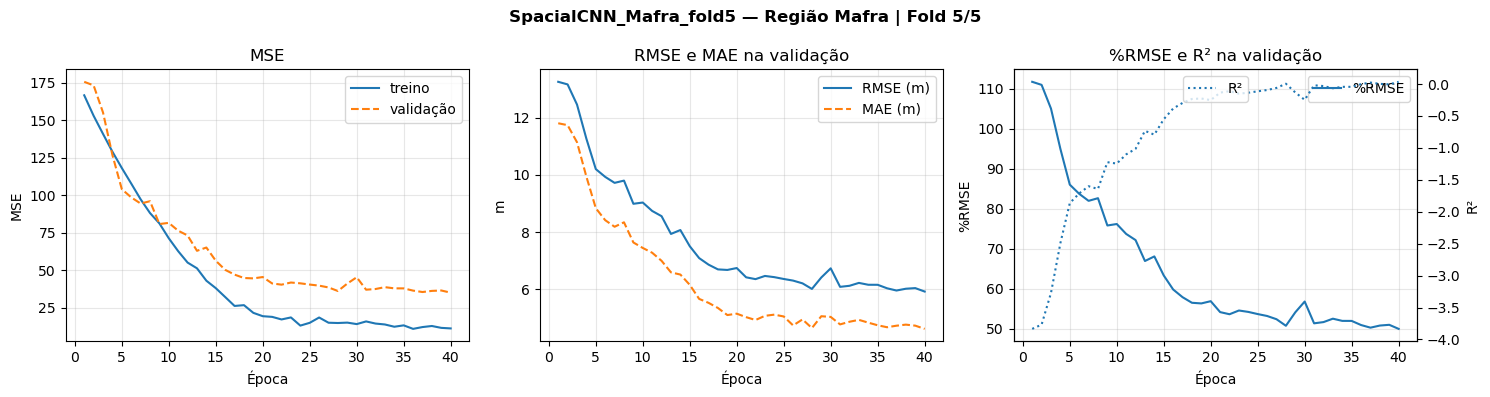

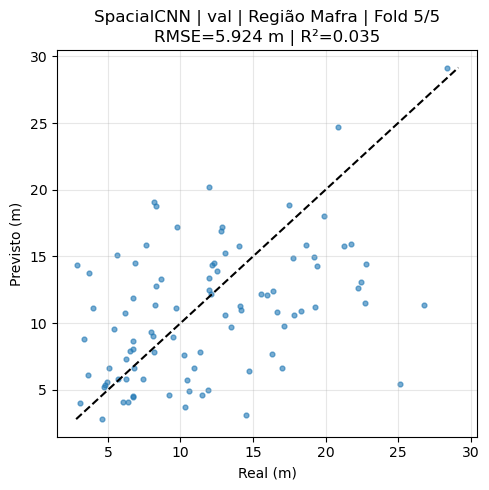

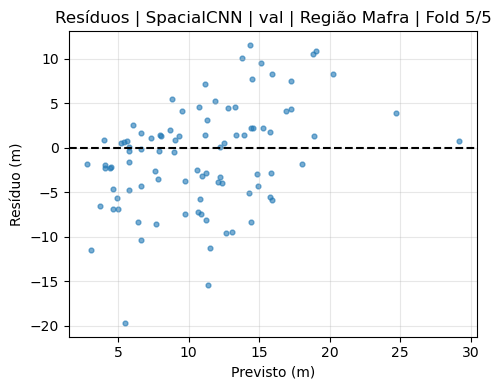


Distribuição das classes de altura por fold — Mafra


height_class,0,1,2,3,4
fold,,,,,
1,19,19,19,18,18
2,19,18,19,19,18
3,18,18,19,19,19
4,19,18,18,18,19
5,19,18,18,18,19



#################################################################
 REGIÃO: Monsanto
#################################################################

Limites das classes de altura:
  Classe 0: 2.54 m até 9.67 m
  Classe 1: 9.67 m até 12.69 m
  Classe 2: 12.69 m até 16.02 m
  Classe 3: 16.02 m até 20.38 m
  Classe 4: 20.38 m até 37.62 m

 Região Monsanto | Fold 1/5
Treino: 364 amostras
Validação: 91 amostras
Regiões treino: ['Monsanto']
Regiões validação: ['Monsanto']
Normalização concluída | média_treino≈0.00002 | std_treino≈0.99993

y_train: média=14.922 m | std=6.379 m | min=2.54 m | max=37.62 m
y_val:   média=14.563 m | std=6.103 m | min=3.06 m | max=29.40 m

Arquitetura: SpacialCNN
Parâmetros totais: 1,298,049 | treináveis: 1,298,049

────────────────────────────────────────────────────────────────────────────────────────
 Época    MSE_tr   MSE_val   RMSE_val   %RMSE      MAE      R²         LR   s/ep     ETA
───────────────────────────────────────────────────────────────────────

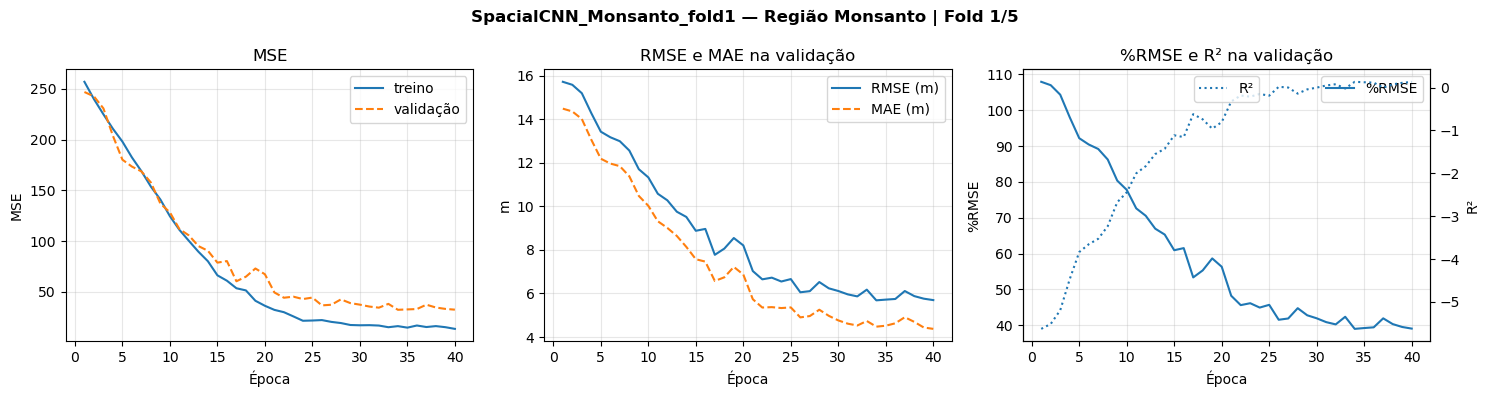

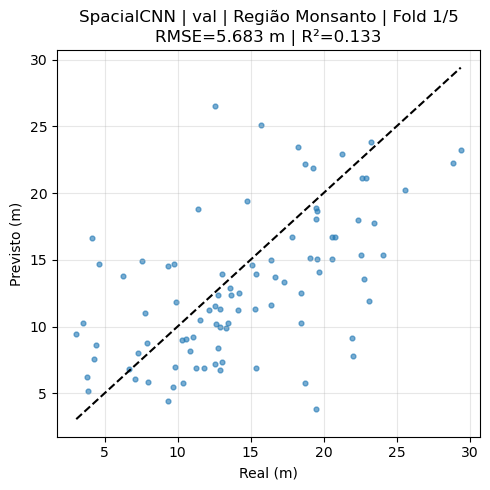

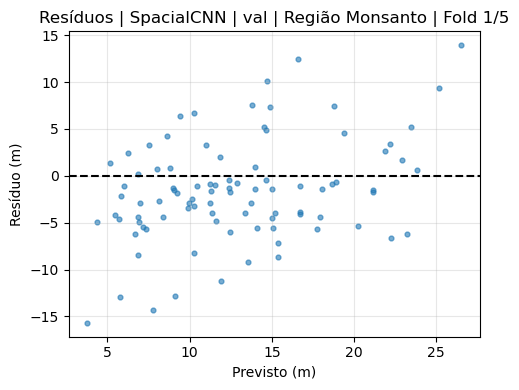


 Região Monsanto | Fold 2/5
Treino: 364 amostras
Validação: 91 amostras
Regiões treino: ['Monsanto']
Regiões validação: ['Monsanto']
Normalização concluída | média_treino≈0.00001 | std_treino≈0.99996

y_train: média=14.819 m | std=6.309 m | min=2.54 m | max=37.62 m
y_val:   média=14.975 m | std=6.391 m | min=2.95 m | max=29.84 m

Arquitetura: SpacialCNN
Parâmetros totais: 1,298,049 | treináveis: 1,298,049

────────────────────────────────────────────────────────────────────────────────────────
 Época    MSE_tr   MSE_val   RMSE_val   %RMSE      MAE      R²         LR   s/ep     ETA
────────────────────────────────────────────────────────────────────────────────────────
     1  253.4564  262.6264    16.206m  108.2%  14.894m  -5.430   3.00e-04   0.3s     11s ⭐
     2  237.8025  257.5587    16.049m  107.2%  14.744m  -5.306   3.00e-04   0.3s     10s ⭐
     3  222.0627  238.8275    15.454m  103.2%  14.184m  -4.847   3.00e-04   0.2s     10s ⭐
     4  207.9415  196.9943    14.035m   93.7%  12

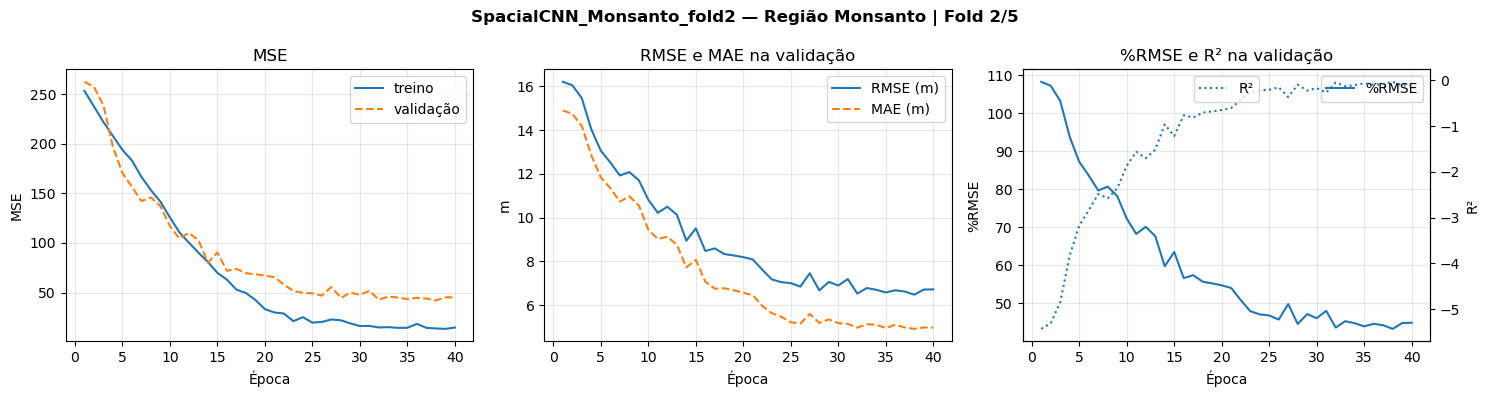

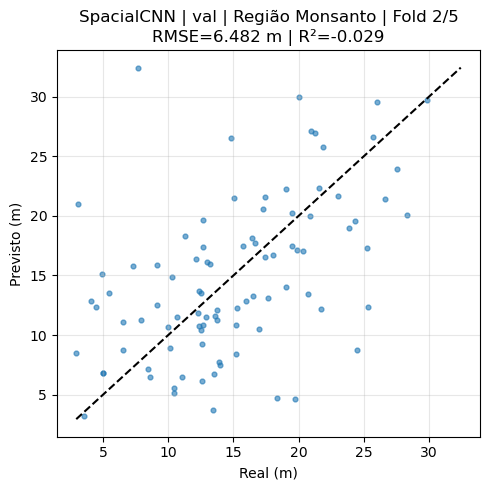

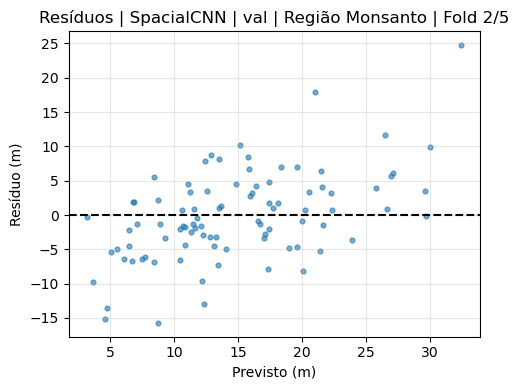


 Região Monsanto | Fold 3/5
Treino: 364 amostras
Validação: 91 amostras
Regiões treino: ['Monsanto']
Regiões validação: ['Monsanto']
Normalização concluída | média_treino≈0.00001 | std_treino≈0.99993

y_train: média=14.805 m | std=6.260 m | min=2.58 m | max=37.62 m
y_val:   média=15.031 m | std=6.580 m | min=2.54 m | max=35.20 m

Arquitetura: SpacialCNN
Parâmetros totais: 1,298,049 | treináveis: 1,298,049

────────────────────────────────────────────────────────────────────────────────────────
 Época    MSE_tr   MSE_val   RMSE_val   %RMSE      MAE      R²         LR   s/ep     ETA
────────────────────────────────────────────────────────────────────────────────────────
     1  252.6505  267.3635    16.351m  108.8%  14.971m  -5.176   3.00e-04   0.3s     10s ⭐
     2  237.5405  262.6632    16.207m  107.8%  14.835m  -5.067   3.00e-04   0.3s     10s ⭐
     3  221.8991  241.9226    15.554m  103.5%  14.226m  -4.588   3.00e-04   0.3s     10s ⭐
     4  206.7315  206.0222    14.353m   95.5%  13

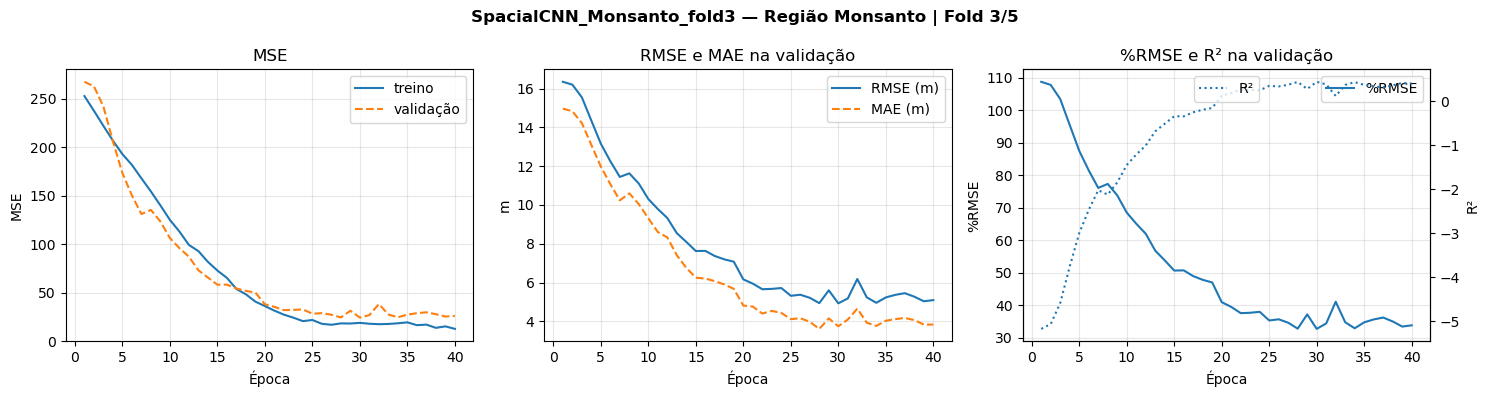

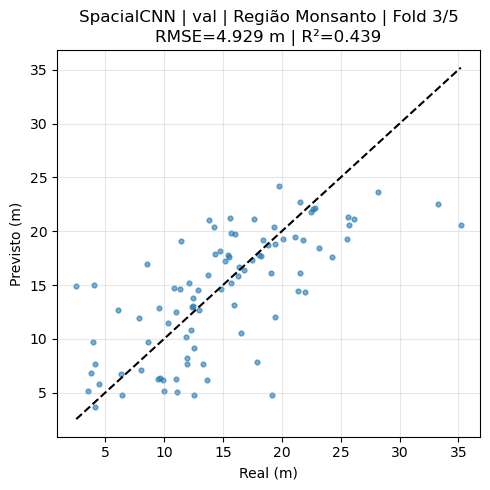

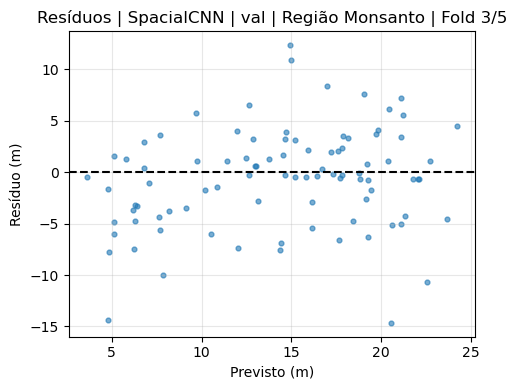


 Região Monsanto | Fold 4/5
Treino: 364 amostras
Validação: 91 amostras
Regiões treino: ['Monsanto']
Regiões validação: ['Monsanto']
Normalização concluída | média_treino≈0.00002 | std_treino≈0.99993

y_train: média=14.883 m | std=6.350 m | min=2.54 m | max=37.62 m
y_val:   média=14.721 m | std=6.227 m | min=2.58 m | max=28.57 m

Arquitetura: SpacialCNN
Parâmetros totais: 1,298,049 | treináveis: 1,298,049

────────────────────────────────────────────────────────────────────────────────────────
 Época    MSE_tr   MSE_val   RMSE_val   %RMSE      MAE      R²         LR   s/ep     ETA
────────────────────────────────────────────────────────────────────────────────────────
     1  256.0409  253.1502    15.911m  108.1%  14.643m  -5.528   3.00e-04   0.2s      9s ⭐
     2  239.7381  248.4619    15.763m  107.1%  14.500m  -5.407   3.00e-04   0.2s      9s ⭐
     3  223.9825  228.4564    15.115m  102.7%  13.924m  -4.891   3.00e-04   0.2s      9s ⭐
     4  208.8369  196.6925    14.025m   95.3%  12

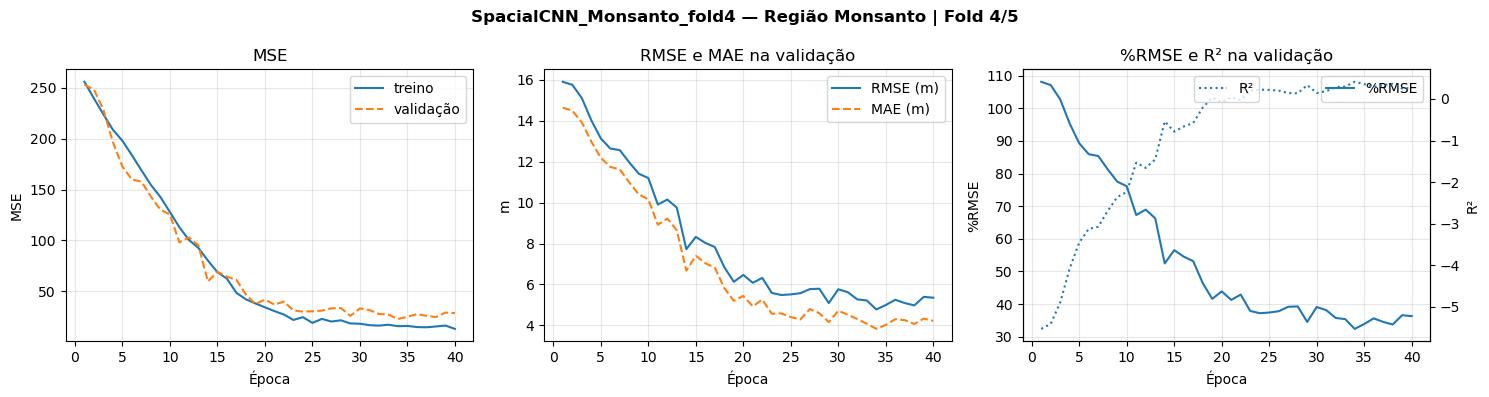

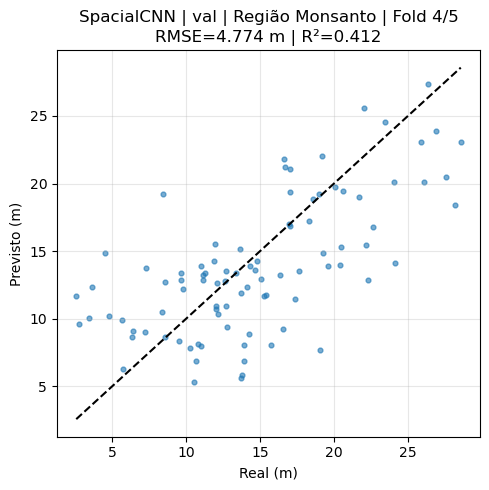

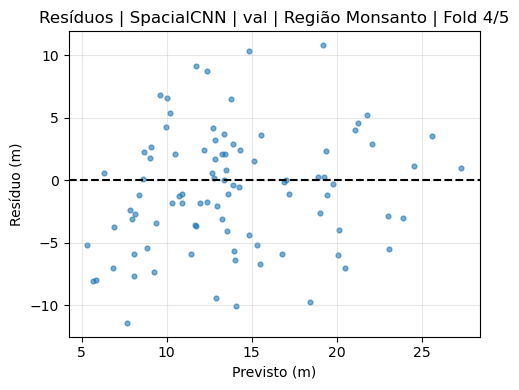


 Região Monsanto | Fold 5/5
Treino: 364 amostras
Validação: 91 amostras
Regiões treino: ['Monsanto']
Regiões validação: ['Monsanto']
Normalização concluída | média_treino≈0.00001 | std_treino≈0.99993

y_train: média=14.822 m | std=6.331 m | min=2.54 m | max=35.20 m
y_val:   média=14.962 m | std=6.307 m | min=3.18 m | max=37.62 m

Arquitetura: SpacialCNN
Parâmetros totais: 1,298,049 | treináveis: 1,298,049

────────────────────────────────────────────────────────────────────────────────────────
 Época    MSE_tr   MSE_val   RMSE_val   %RMSE      MAE      R²         LR   s/ep     ETA
────────────────────────────────────────────────────────────────────────────────────────
     1  253.6652  261.4634    16.170m  108.1%  14.891m  -5.573   3.00e-04   0.2s      9s ⭐
     2  236.8513  257.4380    16.045m  107.2%  14.780m  -5.472   3.00e-04   0.3s      9s ⭐
     3  222.7722  237.0160    15.395m  102.9%  14.180m  -4.959   3.00e-04   0.3s     10s ⭐
     4  207.7560  204.5138    14.301m   95.6%  13

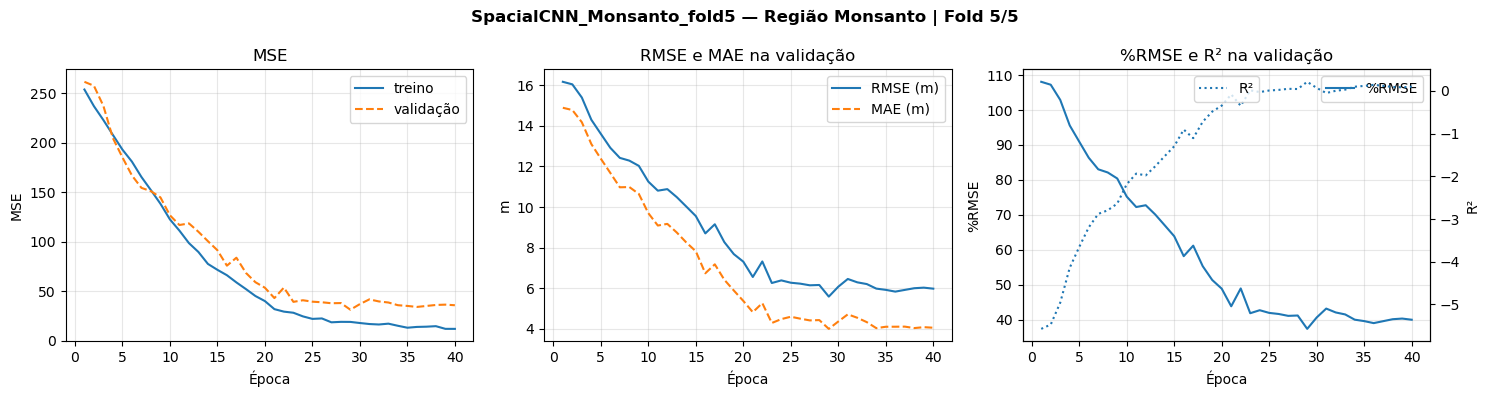

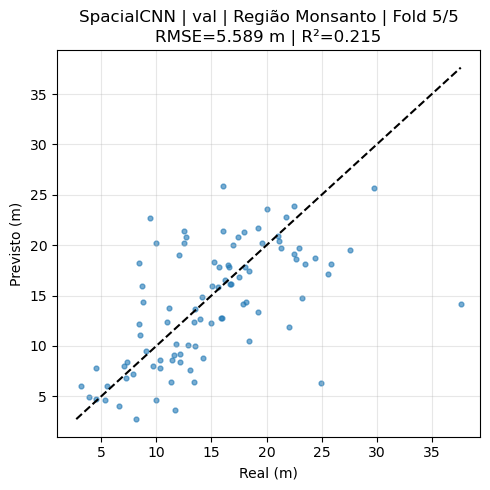

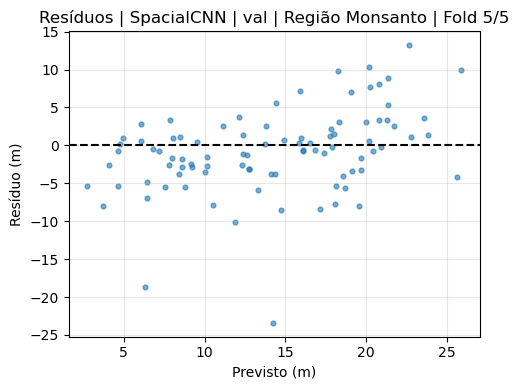


Distribuição das classes de altura por fold — Monsanto


height_class,0,1,2,3,4
fold,,,,,
1,18,18,19,18,18
2,18,18,18,18,19
3,18,19,18,18,18
4,19,18,18,18,18
5,19,18,18,18,18



#################################################################
 REGIÃO: Pombal
#################################################################

Limites das classes de altura:
  Classe 0: 2.58 m até 7.32 m
  Classe 1: 7.32 m até 11.09 m
  Classe 2: 11.09 m até 13.91 m
  Classe 3: 13.91 m até 17.66 m
  Classe 4: 17.66 m até 41.90 m

 Região Pombal | Fold 1/5
Treino: 680 amostras
Validação: 170 amostras
Regiões treino: ['Pombal']
Regiões validação: ['Pombal']
Normalização concluída | média_treino≈0.00000 | std_treino≈0.99999

y_train: média=12.824 m | std=6.126 m | min=2.58 m | max=41.90 m
y_val:   média=12.805 m | std=5.805 m | min=2.69 m | max=31.07 m

Arquitetura: SpacialCNN
Parâmetros totais: 1,298,049 | treináveis: 1,298,049

────────────────────────────────────────────────────────────────────────────────────────
 Época    MSE_tr   MSE_val   RMSE_val   %RMSE      MAE      R²         LR   s/ep     ETA
──────────────────────────────────────────────────────────────────────────────

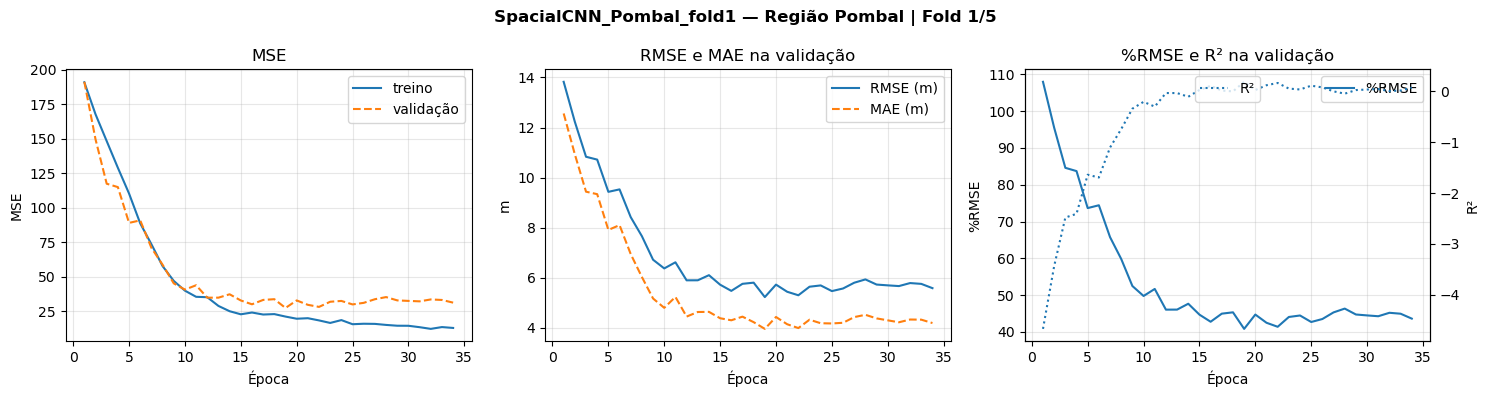

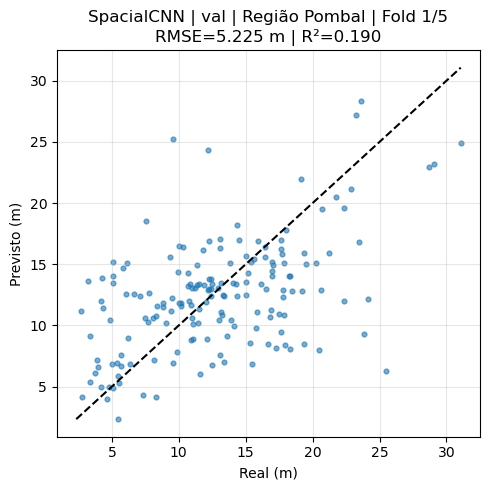

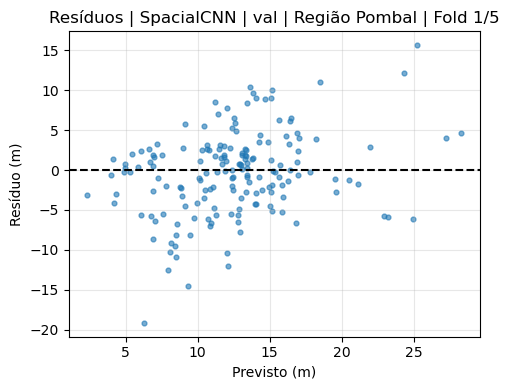


 Região Pombal | Fold 2/5
Treino: 680 amostras
Validação: 170 amostras
Regiões treino: ['Pombal']
Regiões validação: ['Pombal']
Normalização concluída | média_treino≈0.00000 | std_treino≈0.99999

y_train: média=12.809 m | std=5.951 m | min=2.58 m | max=38.79 m
y_val:   média=12.868 m | std=6.492 m | min=2.60 m | max=41.90 m

Arquitetura: SpacialCNN
Parâmetros totais: 1,298,049 | treináveis: 1,298,049

────────────────────────────────────────────────────────────────────────────────────────
 Época    MSE_tr   MSE_val   RMSE_val   %RMSE      MAE      R²         LR   s/ep     ETA
────────────────────────────────────────────────────────────────────────────────────────
     1  188.2669  201.4360    14.193m  110.3%  12.637m  -3.779   3.00e-04   0.6s     23s ⭐
     2  164.1882  162.3044    12.740m   99.0%  11.172m  -2.851   3.00e-04   0.5s     21s ⭐
     3  144.3645  140.3694    11.848m   92.1%  10.225m  -2.330   3.00e-04   0.5s     19s ⭐
     4  126.2732  134.6004    11.602m   90.2%   9.941m

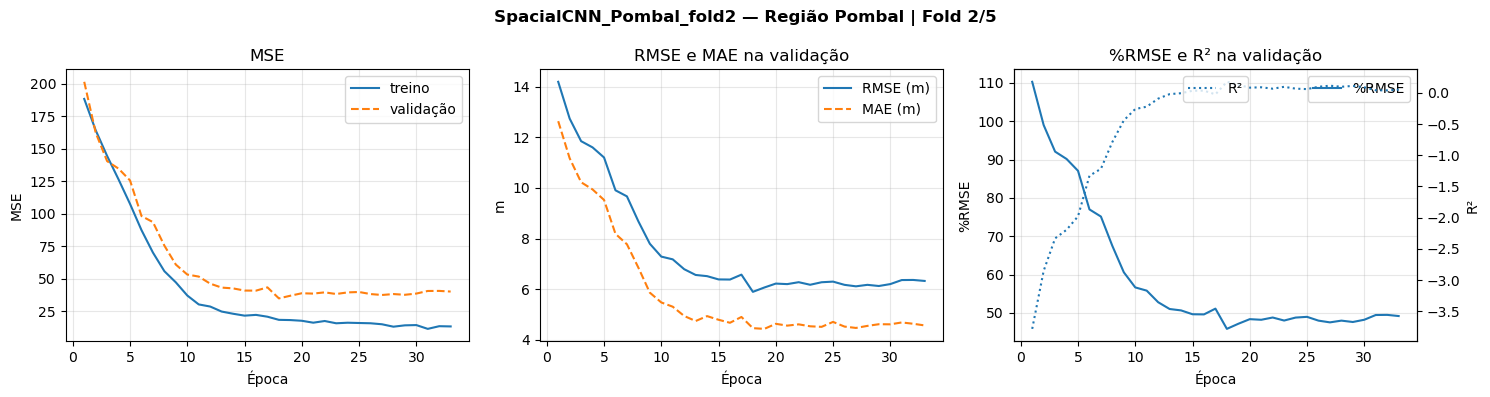

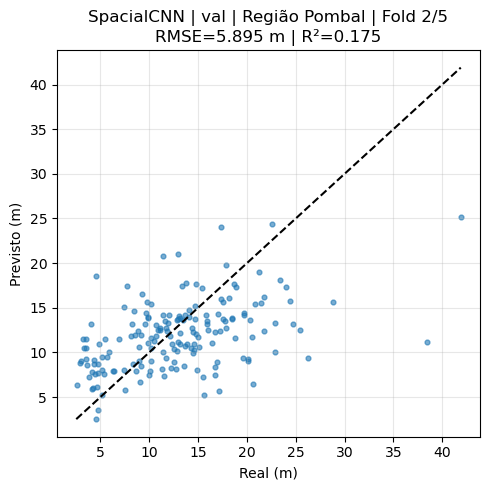

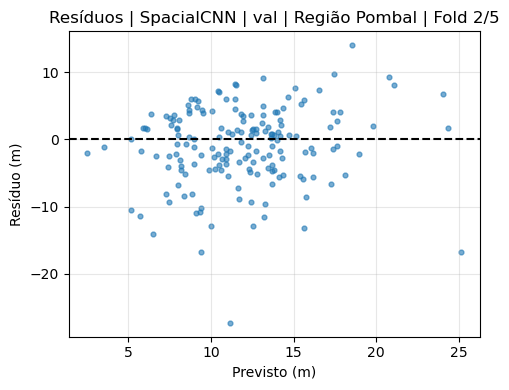


 Região Pombal | Fold 3/5
Treino: 680 amostras
Validação: 170 amostras
Regiões treino: ['Pombal']
Regiões validação: ['Pombal']
Normalização concluída | média_treino≈0.00000 | std_treino≈0.99999

y_train: média=12.833 m | std=6.110 m | min=2.58 m | max=41.90 m
y_val:   média=12.771 m | std=5.871 m | min=2.80 m | max=32.72 m

Arquitetura: SpacialCNN
Parâmetros totais: 1,298,049 | treináveis: 1,298,049

────────────────────────────────────────────────────────────────────────────────────────
 Época    MSE_tr   MSE_val   RMSE_val   %RMSE      MAE      R²         LR   s/ep     ETA
────────────────────────────────────────────────────────────────────────────────────────
     1  192.0263  192.9637    13.891m  108.8%  12.598m  -4.598   3.00e-04   0.6s     23s ⭐
     2  169.9501  155.4097    12.466m   97.6%  11.216m  -3.508   3.00e-04   0.5s     21s ⭐
     3  149.5785  126.2310    11.235m   88.0%  10.011m  -2.662   3.00e-04   0.5s     20s ⭐
     4  129.8982  123.4505    11.111m   87.0%   9.819m

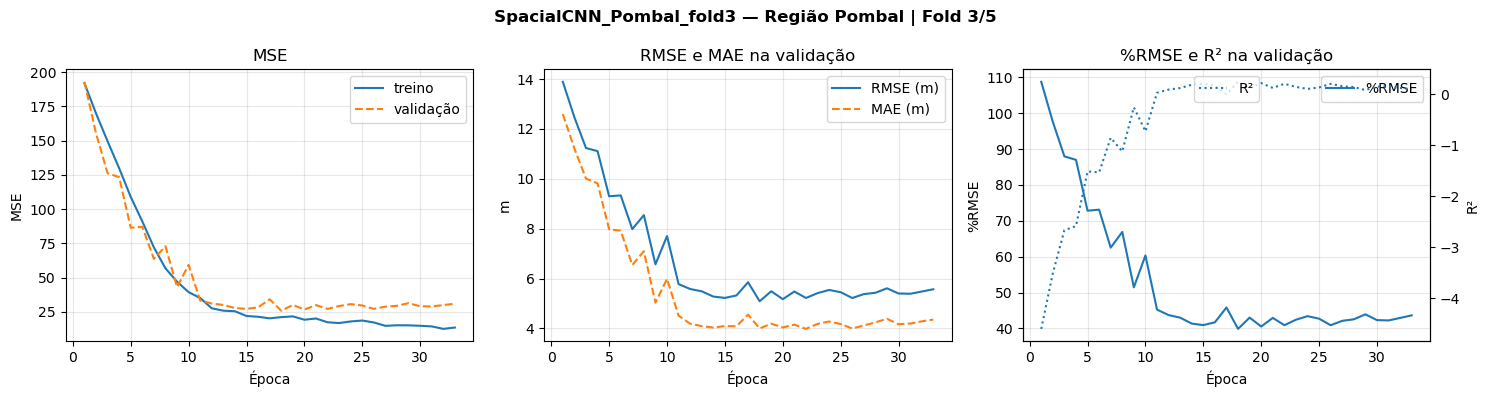

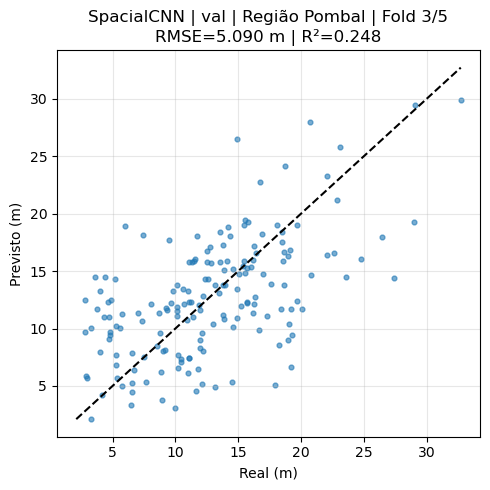

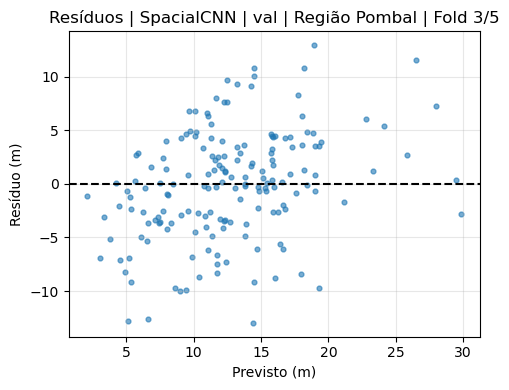


 Região Pombal | Fold 4/5
Treino: 680 amostras
Validação: 170 amostras
Regiões treino: ['Pombal']
Regiões validação: ['Pombal']
Normalização concluída | média_treino≈0.00000 | std_treino≈0.99999

y_train: média=12.835 m | std=6.111 m | min=2.60 m | max=41.90 m
y_val:   média=12.763 m | std=5.866 m | min=2.58 m | max=34.15 m

Arquitetura: SpacialCNN
Parâmetros totais: 1,298,049 | treináveis: 1,298,049

────────────────────────────────────────────────────────────────────────────────────────
 Época    MSE_tr   MSE_val   RMSE_val   %RMSE      MAE      R²         LR   s/ep     ETA
────────────────────────────────────────────────────────────────────────────────────────
     1  191.9184  191.7819    13.849m  108.5%  12.560m  -4.573   3.00e-04   0.6s     23s ⭐
     2  168.3622  148.4292    12.183m   95.5%  10.863m  -3.313   3.00e-04   0.5s     21s ⭐
     3  149.3933  116.6884    10.802m   84.6%   9.522m  -2.391   3.00e-04   0.5s     20s ⭐
     4  128.7994  109.1510    10.448m   81.9%   9.173m

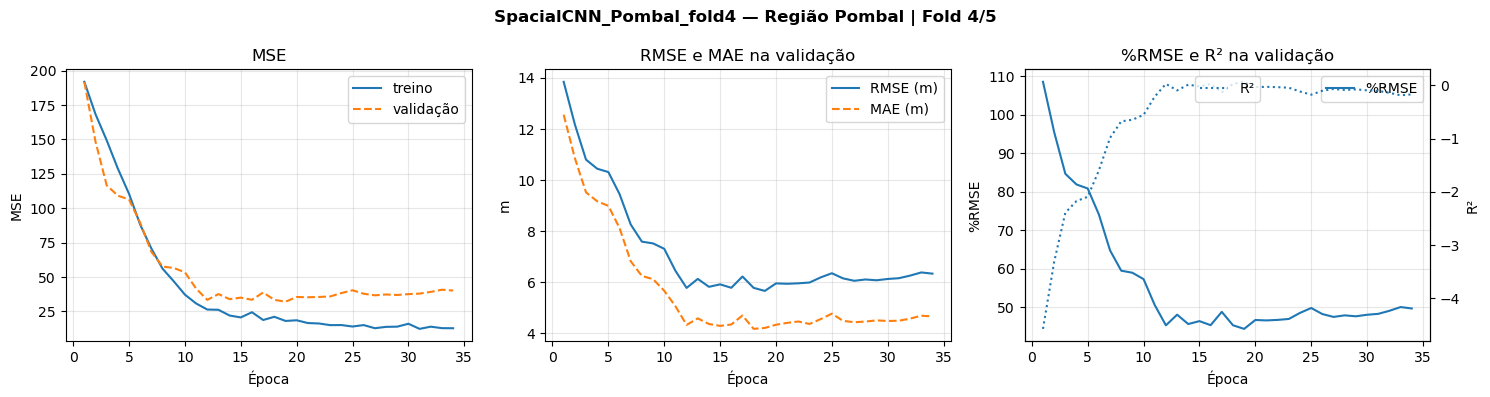

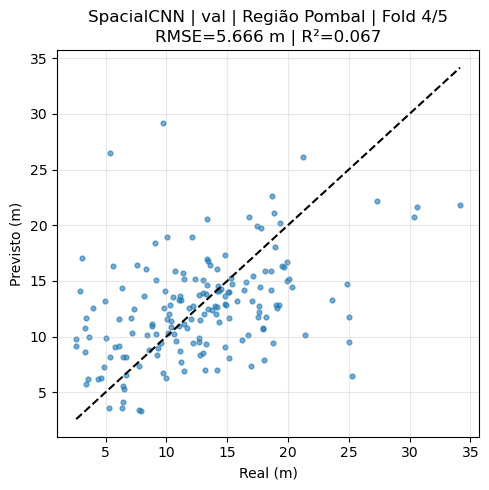

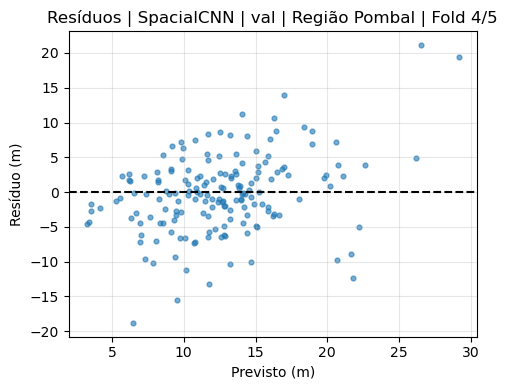


 Região Pombal | Fold 5/5
Treino: 680 amostras
Validação: 170 amostras
Regiões treino: ['Pombal']
Regiões validação: ['Pombal']
Normalização concluída | média_treino≈0.00000 | std_treino≈0.99999

y_train: média=12.802 m | std=6.015 m | min=2.58 m | max=41.90 m
y_val:   média=12.896 m | std=6.250 m | min=3.09 m | max=38.79 m

Arquitetura: SpacialCNN
Parâmetros totais: 1,298,049 | treináveis: 1,298,049

────────────────────────────────────────────────────────────────────────────────────────
 Época    MSE_tr   MSE_val   RMSE_val   %RMSE      MAE      R²         LR   s/ep     ETA
────────────────────────────────────────────────────────────────────────────────────────
     1  189.3704  200.6783    14.166m  109.9%  12.729m  -4.137   3.00e-04   0.5s     21s ⭐
     2  166.5662  156.5130    12.511m   97.0%  11.105m  -3.007   3.00e-04   0.5s     19s ⭐
     3  147.7054  126.0880    11.229m   87.1%   9.784m  -2.228   3.00e-04   0.4s     18s ⭐
     4  127.5143  112.3688    10.600m   82.2%   9.167m

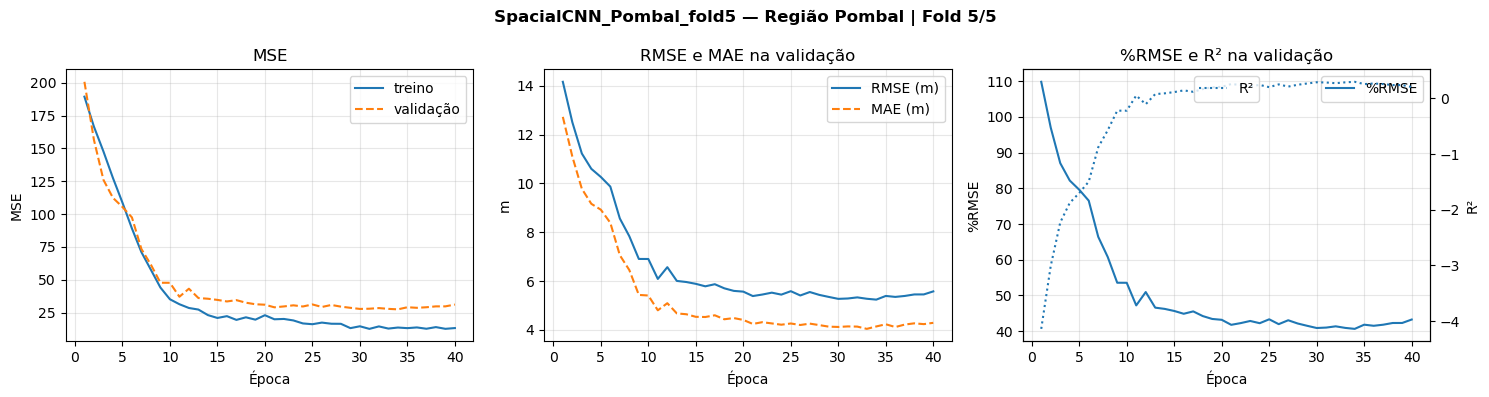

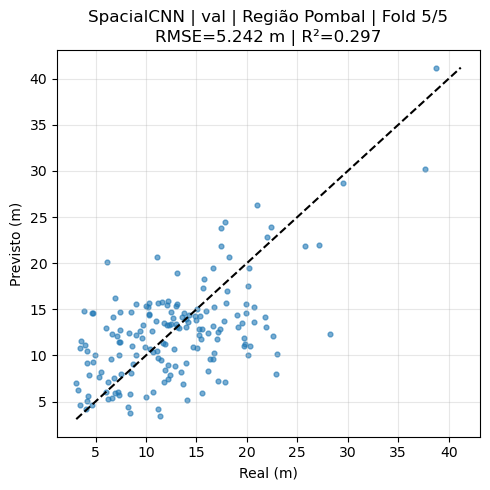

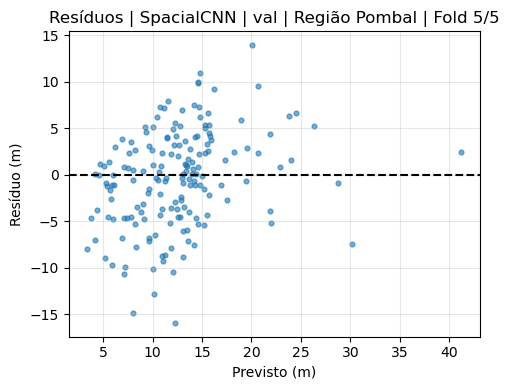


Distribuição das classes de altura por fold — Pombal


height_class,0,1,2,3,4
fold,,,,,
1,34,34,34,34,34
2,34,34,34,34,34
3,34,34,34,34,34
4,34,34,34,34,34
5,34,34,34,34,34



#################################################################
 REGIÃO: SerraLousa
#################################################################

Limites das classes de altura:
  Classe 0: 2.42 m até 8.68 m
  Classe 1: 8.68 m até 13.53 m
  Classe 2: 13.53 m até 18.14 m
  Classe 3: 18.14 m até 23.25 m
  Classe 4: 23.25 m até 51.46 m

 Região SerraLousa | Fold 1/5
Treino: 4660 amostras
Validação: 1165 amostras
Regiões treino: ['SerraLousa']
Regiões validação: ['SerraLousa']
Normalização concluída | média_treino≈-0.00001 | std_treino≈0.99972

y_train: média=16.374 m | std=7.903 m | min=2.43 m | max=49.22 m
y_val:   média=16.399 m | std=8.182 m | min=2.42 m | max=51.46 m

Arquitetura: SpacialCNN
Parâmetros totais: 1,298,049 | treináveis: 1,298,049

────────────────────────────────────────────────────────────────────────────────────────
 Época    MSE_tr   MSE_val   RMSE_val   %RMSE      MAE      R²         LR   s/ep     ETA
───────────────────────────────────────────────────────────

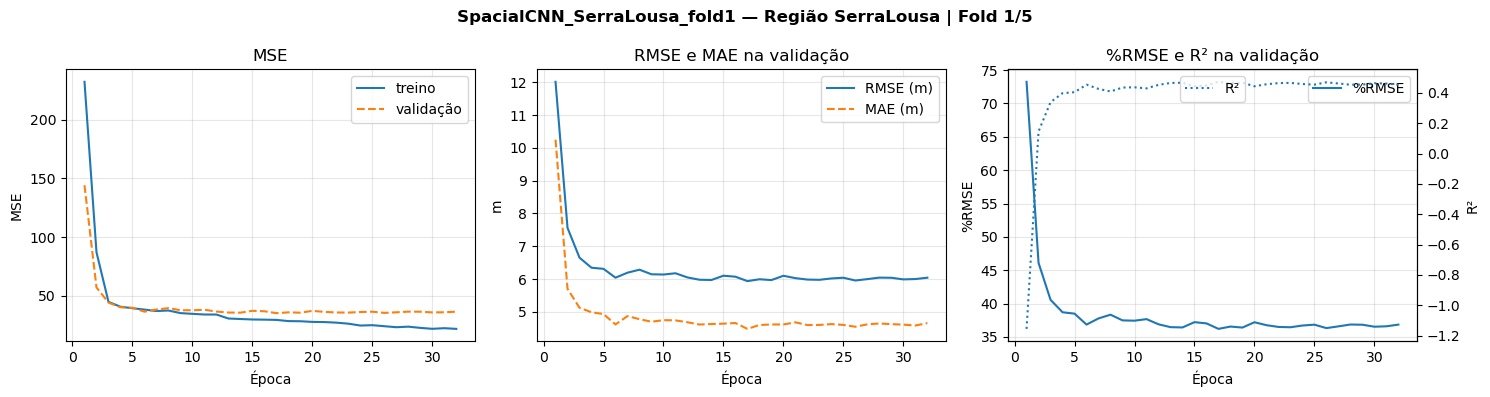

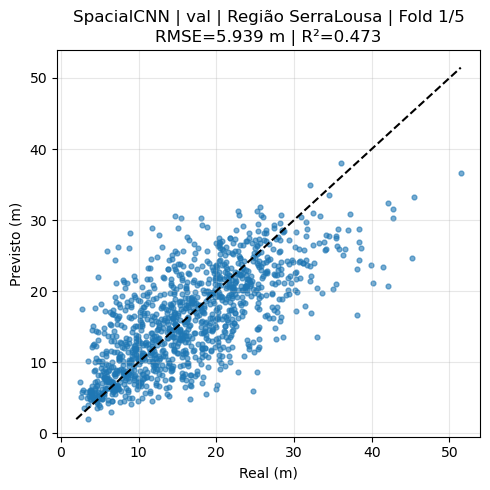

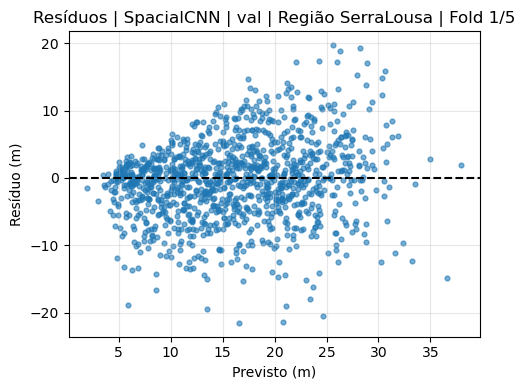


 Região SerraLousa | Fold 2/5
Treino: 4660 amostras
Validação: 1165 amostras
Regiões treino: ['SerraLousa']
Regiões validação: ['SerraLousa']
Normalização concluída | média_treino≈-0.00001 | std_treino≈0.99972

y_train: média=16.364 m | std=7.940 m | min=2.42 m | max=51.46 m
y_val:   média=16.441 m | std=8.040 m | min=2.43 m | max=49.22 m

Arquitetura: SpacialCNN
Parâmetros totais: 1,298,049 | treináveis: 1,298,049

────────────────────────────────────────────────────────────────────────────────────────
 Época    MSE_tr   MSE_val   RMSE_val   %RMSE      MAE      R²         LR   s/ep     ETA
────────────────────────────────────────────────────────────────────────────────────────
     1  232.6406  140.4287    11.850m   72.1%  10.079m  -1.173   3.00e-04   3.9s   2m30s ⭐
     2   88.2115   53.5328     7.317m   44.5%   5.642m   0.172   3.00e-04   3.5s   2m19s ⭐
     3   45.0971   45.0327     6.711m   40.8%   5.101m   0.303   3.00e-04   3.4s   2m12s ⭐
     4   42.3154   36.4921     6.041m  

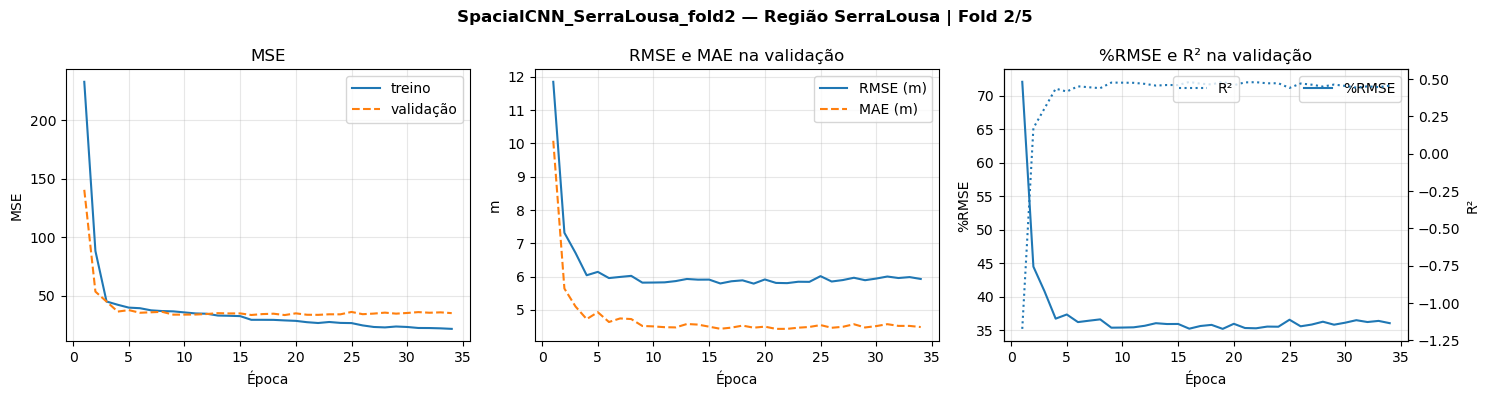

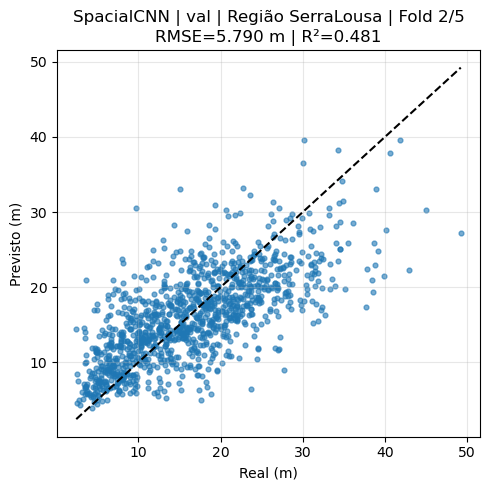

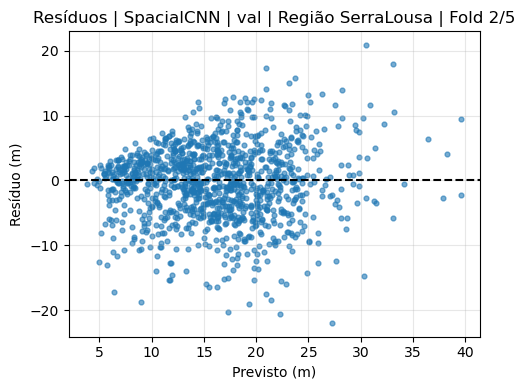


 Região SerraLousa | Fold 3/5
Treino: 4660 amostras
Validação: 1165 amostras
Regiões treino: ['SerraLousa']
Regiões validação: ['SerraLousa']
Normalização concluída | média_treino≈-0.00000 | std_treino≈0.99970

y_train: média=16.382 m | std=7.967 m | min=2.42 m | max=51.46 m
y_val:   média=16.366 m | std=7.929 m | min=2.62 m | max=48.72 m

Arquitetura: SpacialCNN
Parâmetros totais: 1,298,049 | treináveis: 1,298,049

────────────────────────────────────────────────────────────────────────────────────────
 Época    MSE_tr   MSE_val   RMSE_val   %RMSE      MAE      R²         LR   s/ep     ETA
────────────────────────────────────────────────────────────────────────────────────────
     1  231.9756  139.3800    11.806m   72.1%  10.042m  -1.217   3.00e-04   3.4s   2m10s ⭐
     2   87.6939   60.1572     7.756m   47.4%   6.036m   0.043   3.00e-04   3.1s   2m01s ⭐
     3   45.3495   42.4089     6.512m   39.8%   5.096m   0.325   3.00e-04   3.1s   1m57s ⭐
     4   41.5671   38.7730     6.227m  

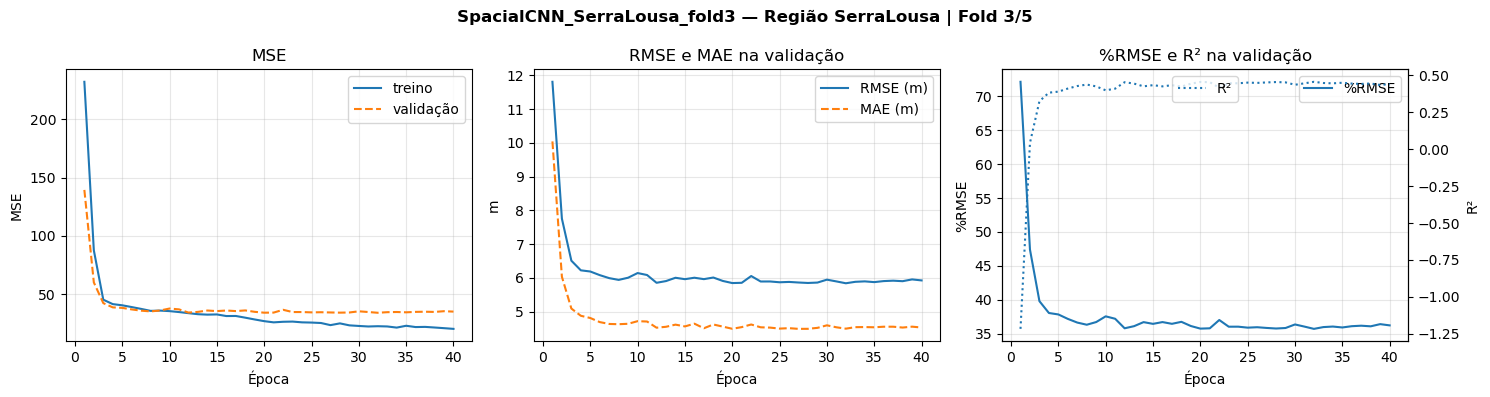

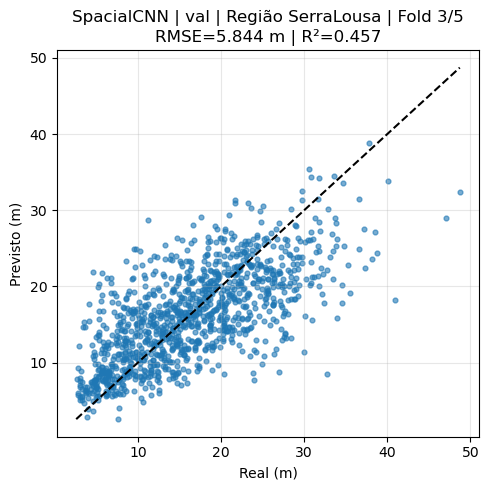

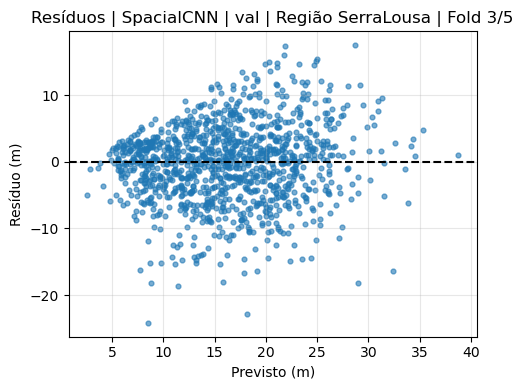


 Região SerraLousa | Fold 4/5
Treino: 4660 amostras
Validação: 1165 amostras
Regiões treino: ['SerraLousa']
Regiões validação: ['SerraLousa']
Normalização concluída | média_treino≈-0.00001 | std_treino≈0.99971

y_train: média=16.381 m | std=8.000 m | min=2.42 m | max=51.46 m
y_val:   média=16.371 m | std=7.798 m | min=2.79 m | max=47.71 m

Arquitetura: SpacialCNN
Parâmetros totais: 1,298,049 | treináveis: 1,298,049

────────────────────────────────────────────────────────────────────────────────────────
 Época    MSE_tr   MSE_val   RMSE_val   %RMSE      MAE      R²         LR   s/ep     ETA
────────────────────────────────────────────────────────────────────────────────────────
     1  233.4736  134.3764    11.592m   70.8%   9.904m  -1.210   3.00e-04   3.3s   2m08s ⭐
     2   85.9878   52.6017     7.253m   44.3%   5.527m   0.135   3.00e-04   3.1s   2m01s ⭐
     3   46.3416   37.3100     6.108m   37.3%   4.792m   0.386   3.00e-04   3.1s   1m56s ⭐
     4   41.9555   36.7368     6.061m  

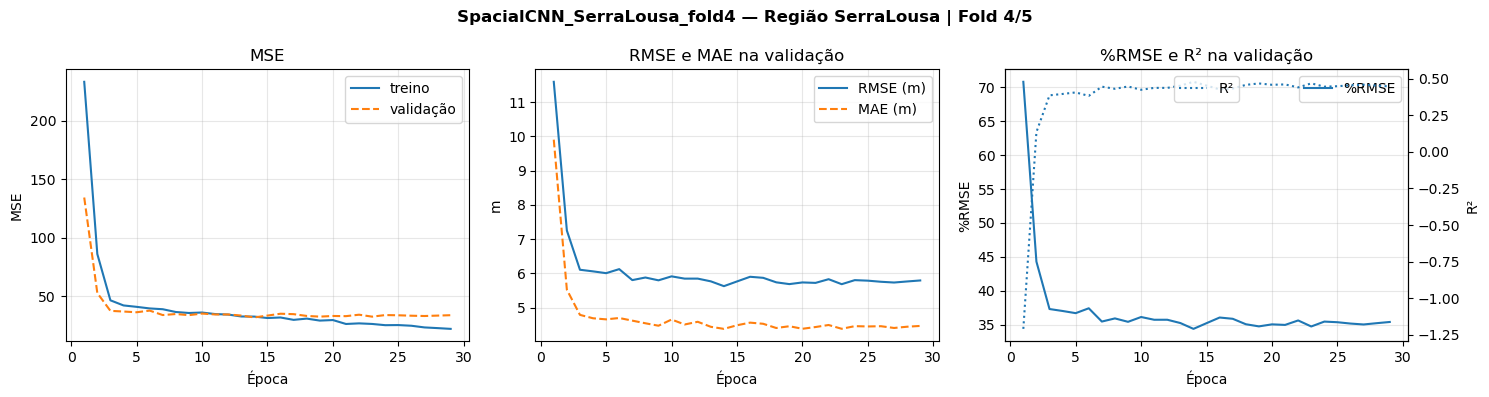

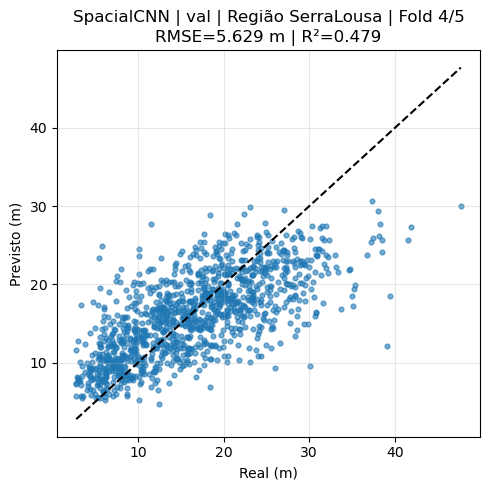

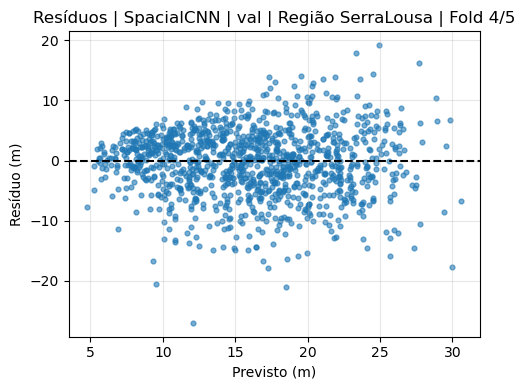


 Região SerraLousa | Fold 5/5
Treino: 4660 amostras
Validação: 1165 amostras
Regiões treino: ['SerraLousa']
Regiões validação: ['SerraLousa']
Normalização concluída | média_treino≈-0.00001 | std_treino≈0.99970

y_train: média=16.394 m | std=7.988 m | min=2.42 m | max=51.46 m
y_val:   média=16.318 m | std=7.843 m | min=2.43 m | max=42.43 m

Arquitetura: SpacialCNN
Parâmetros totais: 1,298,049 | treináveis: 1,298,049

────────────────────────────────────────────────────────────────────────────────────────
 Época    MSE_tr   MSE_val   RMSE_val   %RMSE      MAE      R²         LR   s/ep     ETA
────────────────────────────────────────────────────────────────────────────────────────
     1  232.8413  135.9241    11.659m   71.4%  10.078m  -1.209   3.00e-04   3.3s   2m10s ⭐
     2   87.6682   56.2006     7.497m   45.9%   5.861m   0.086   3.00e-04   3.1s   2m02s ⭐
     3   45.1203   38.4212     6.198m   38.0%   4.842m   0.375   3.00e-04   3.1s   1m57s ⭐
     5   39.0763   43.0582     6.562m  

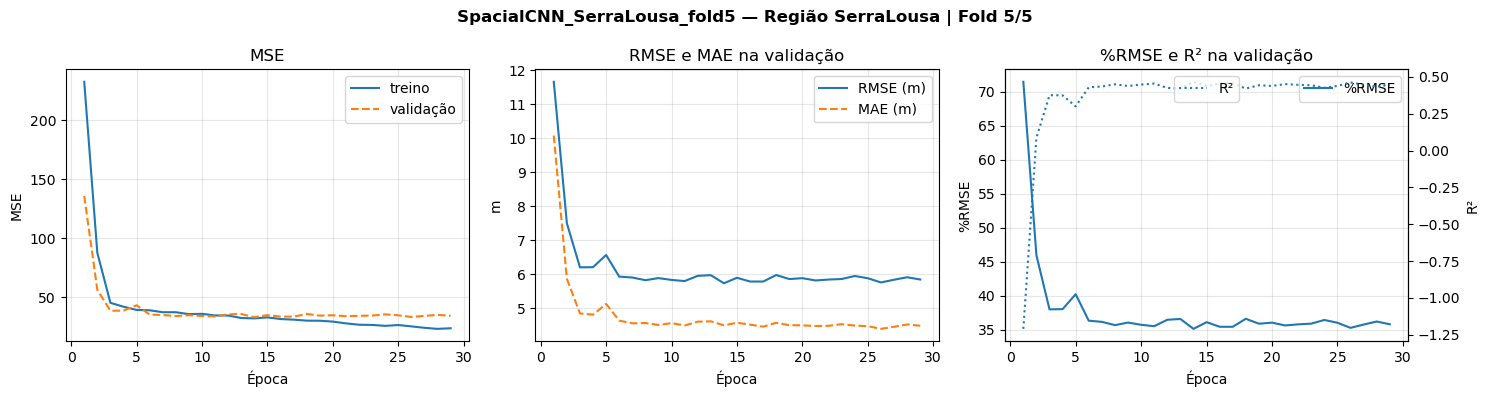

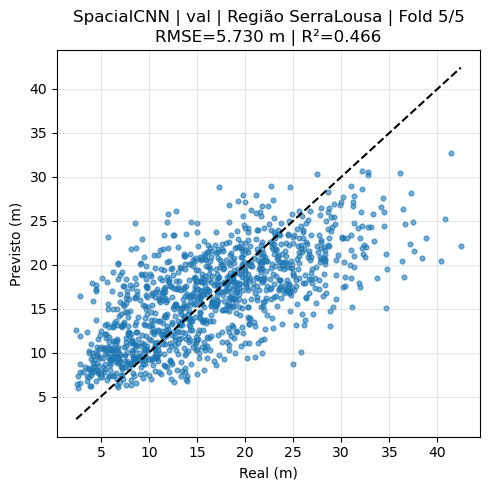

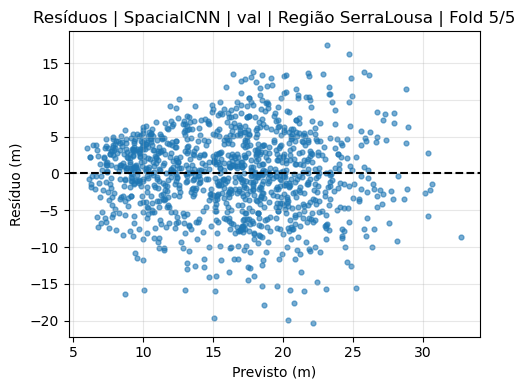


Distribuição das classes de altura por fold — SerraLousa


height_class,0,1,2,3,4
fold,,,,,
1,234,232,233,234,232
2,234,232,233,234,232
3,234,232,233,234,232
4,234,232,233,233,233
5,234,232,234,233,232



#################################################################
 REGIÃO: SintraCascais
#################################################################

Limites das classes de altura:
  Classe 0: 2.50 m até 7.75 m
  Classe 1: 7.75 m até 13.11 m
  Classe 2: 13.11 m até 16.85 m
  Classe 3: 16.85 m até 21.30 m
  Classe 4: 21.30 m até 63.93 m

 Região SintraCascais | Fold 1/5
Treino: 588 amostras
Validação: 148 amostras
Regiões treino: ['SintraCascais']
Regiões validação: ['SintraCascais']
Normalização concluída | média_treino≈-0.00003 | std_treino≈0.99992

y_train: média=15.291 m | std=8.011 m | min=2.50 m | max=53.64 m
y_val:   média=15.530 m | std=8.232 m | min=3.01 m | max=63.93 m

Arquitetura: SpacialCNN
Parâmetros totais: 1,298,049 | treináveis: 1,298,049

────────────────────────────────────────────────────────────────────────────────────────
 Época    MSE_tr   MSE_val   RMSE_val   %RMSE      MAE      R²         LR   s/ep     ETA
─────────────────────────────────────────────────

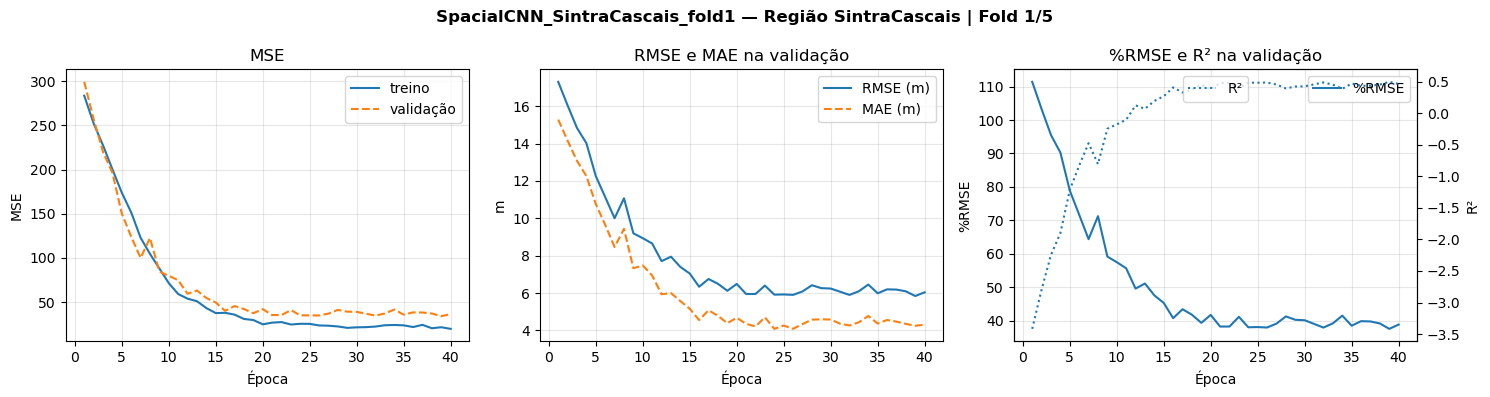

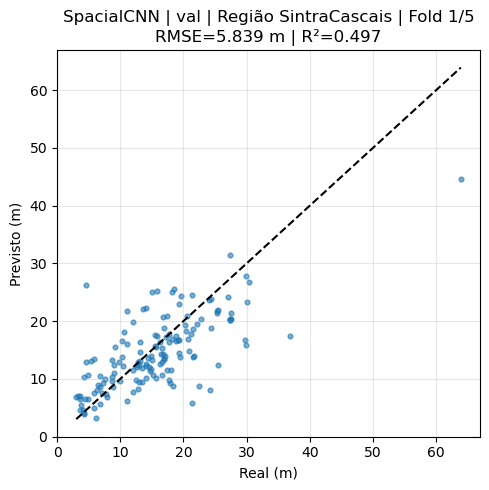

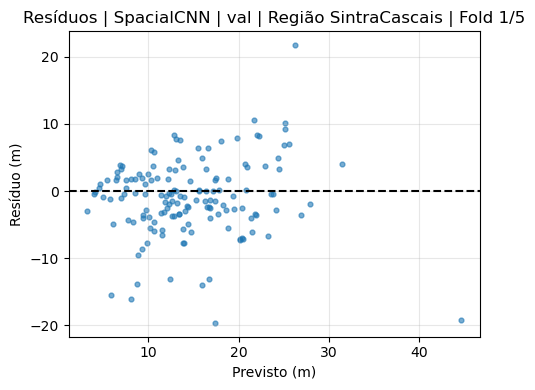


 Região SintraCascais | Fold 2/5
Treino: 589 amostras
Validação: 147 amostras
Regiões treino: ['SintraCascais']
Regiões validação: ['SintraCascais']
Normalização concluída | média_treino≈-0.00003 | std_treino≈0.99996

y_train: média=15.302 m | std=7.881 m | min=2.50 m | max=63.93 m
y_val:   média=15.489 m | std=8.724 m | min=2.62 m | max=53.64 m

Arquitetura: SpacialCNN
Parâmetros totais: 1,298,049 | treináveis: 1,298,049

────────────────────────────────────────────────────────────────────────────────────────
 Época    MSE_tr   MSE_val   RMSE_val   %RMSE      MAE      R²         LR   s/ep     ETA
────────────────────────────────────────────────────────────────────────────────────────
     1  282.6296  307.7733    17.543m  113.3%  15.289m  -3.044   3.00e-04   0.4s     17s ⭐
     2  252.9995  258.3528    16.073m  103.8%  14.116m  -2.395   3.00e-04   0.4s     16s ⭐
     3  226.8359  212.3690    14.573m   94.1%  12.758m  -1.790   3.00e-04   0.4s     15s ⭐
     4  202.4077  197.3928    14

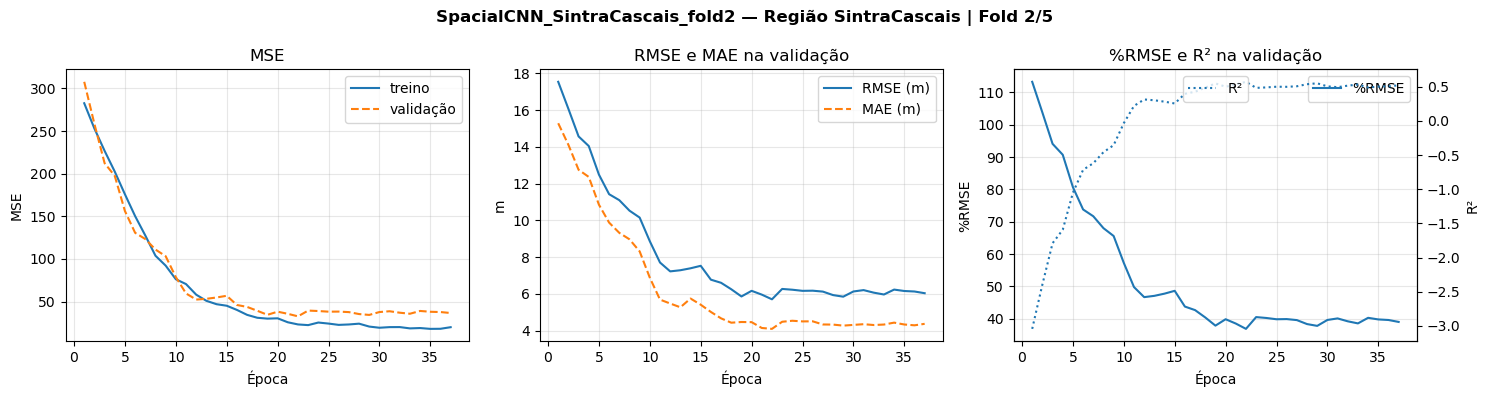

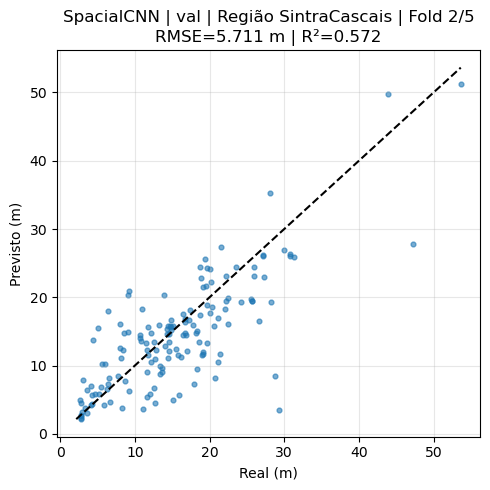

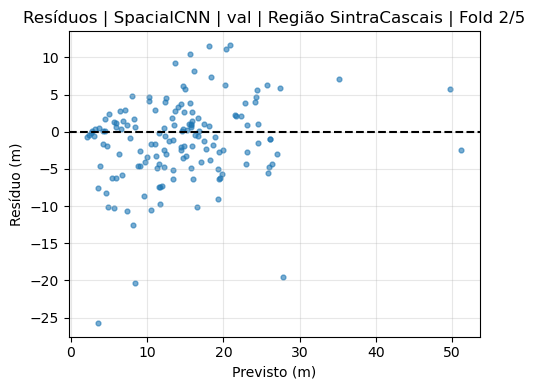


 Região SintraCascais | Fold 3/5
Treino: 589 amostras
Validação: 147 amostras
Regiões treino: ['SintraCascais']
Regiões validação: ['SintraCascais']
Normalização concluída | média_treino≈-0.00002 | std_treino≈0.99993

y_train: média=15.314 m | std=8.032 m | min=2.50 m | max=63.93 m
y_val:   média=15.441 m | std=8.155 m | min=2.60 m | max=41.67 m

Arquitetura: SpacialCNN
Parâmetros totais: 1,298,049 | treináveis: 1,298,049

────────────────────────────────────────────────────────────────────────────────────────
 Época    MSE_tr   MSE_val   RMSE_val   %RMSE      MAE      R²         LR   s/ep     ETA
────────────────────────────────────────────────────────────────────────────────────────
     1  284.7450  297.8866    17.259m  111.8%  15.287m  -3.480   3.00e-04   0.5s     20s ⭐
     2  253.5557  257.5834    16.049m  103.9%  14.379m  -2.873   3.00e-04   0.4s     17s ⭐
     3  229.5589  198.1845    14.078m   91.2%  12.631m  -1.980   3.00e-04   0.4s     16s ⭐
     4  205.6192  187.2267    13

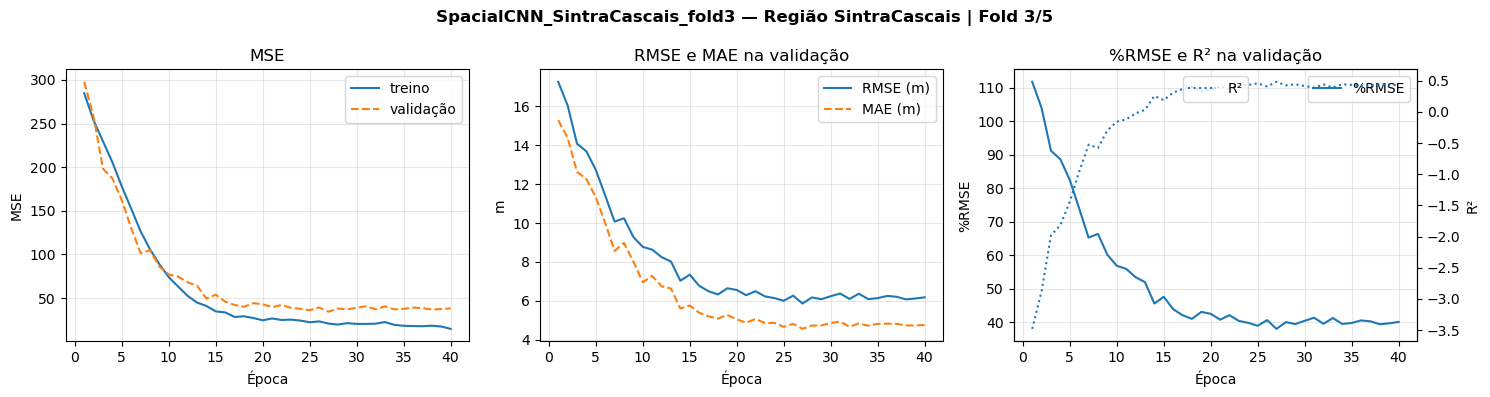

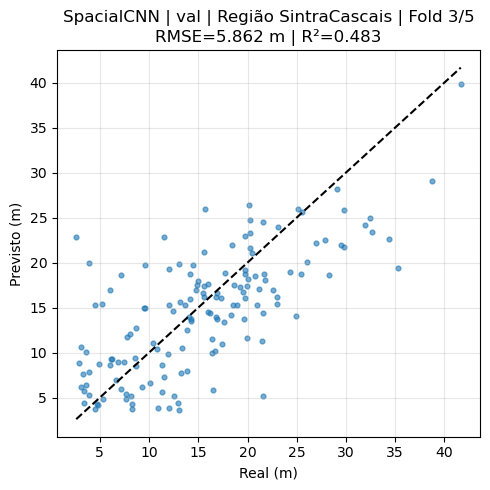

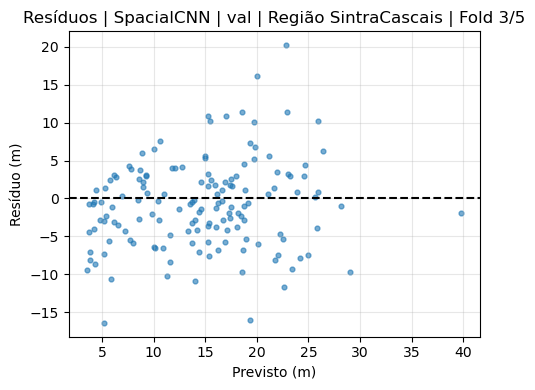


 Região SintraCascais | Fold 4/5
Treino: 589 amostras
Validação: 147 amostras
Regiões treino: ['SintraCascais']
Regiões validação: ['SintraCascais']
Normalização concluída | média_treino≈-0.00002 | std_treino≈0.99992

y_train: média=15.311 m | std=8.093 m | min=2.60 m | max=63.93 m
y_val:   média=15.453 m | std=7.910 m | min=2.50 m | max=44.39 m

Arquitetura: SpacialCNN
Parâmetros totais: 1,298,049 | treináveis: 1,298,049

────────────────────────────────────────────────────────────────────────────────────────
 Época    MSE_tr   MSE_val   RMSE_val   %RMSE      MAE      R²         LR   s/ep     ETA
────────────────────────────────────────────────────────────────────────────────────────
     1  286.8525  293.3784    17.128m  110.8%  15.253m  -3.689   3.00e-04   0.5s     19s ⭐
     2  256.2869  242.1582    15.561m  100.7%  13.976m  -2.870   3.00e-04   0.4s     17s ⭐
     3  230.8563  193.8415    13.923m   90.1%  12.403m  -2.098   3.00e-04   0.4s     16s ⭐
     4  204.6722  178.5334    13

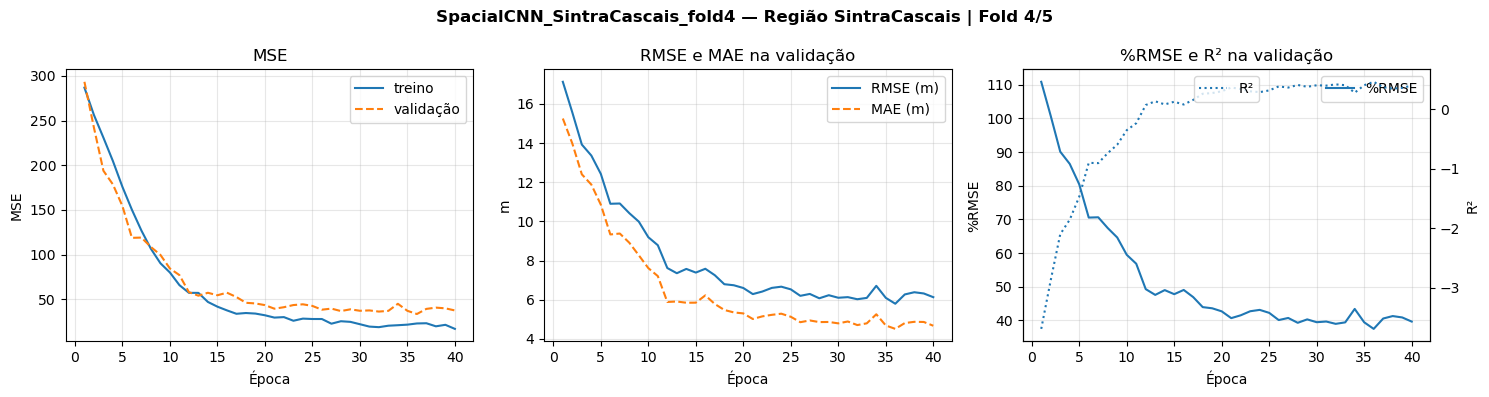

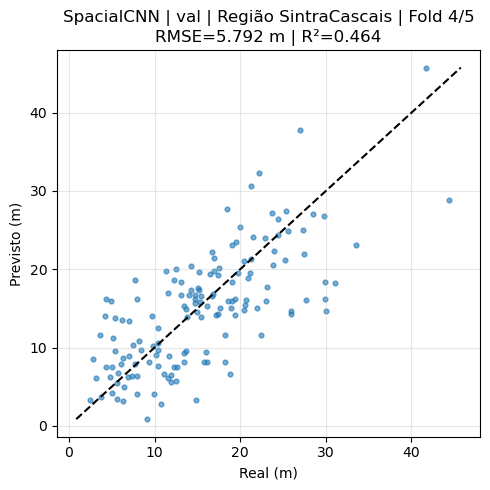

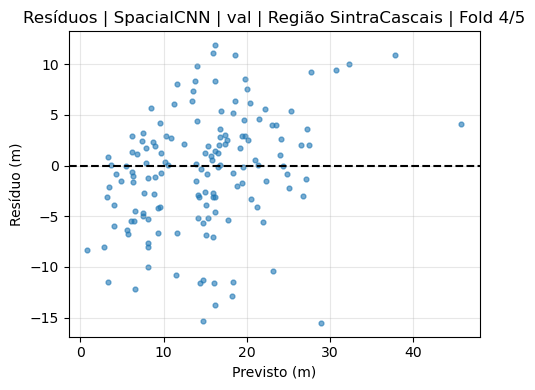


 Região SintraCascais | Fold 5/5
Treino: 589 amostras
Validação: 147 amostras
Regiões treino: ['SintraCascais']
Regiões validação: ['SintraCascais']
Normalização concluída | média_treino≈-0.00003 | std_treino≈0.99992

y_train: média=15.478 m | std=8.261 m | min=2.50 m | max=63.93 m
y_val:   média=14.782 m | std=7.155 m | min=2.65 m | max=31.94 m

Arquitetura: SpacialCNN
Parâmetros totais: 1,298,049 | treináveis: 1,298,049

────────────────────────────────────────────────────────────────────────────────────────
 Época    MSE_tr   MSE_val   RMSE_val   %RMSE      MAE      R²         LR   s/ep     ETA
────────────────────────────────────────────────────────────────────────────────────────
     1  292.9917  263.2101    16.224m  109.8%  14.600m  -4.142   3.00e-04   0.4s     15s ⭐
     2  262.8715  226.0484    15.035m  101.7%  13.627m  -3.416   3.00e-04   0.4s     15s ⭐
     3  237.8802  184.2307    13.573m   91.8%  12.287m  -2.599   3.00e-04   0.4s     14s ⭐
     4  213.1494  161.6655    12

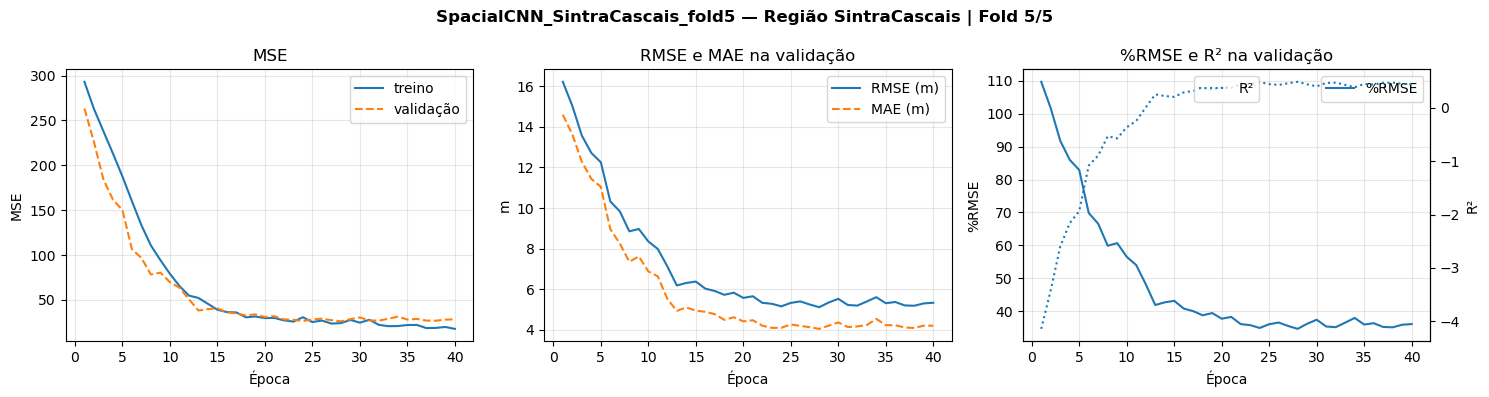

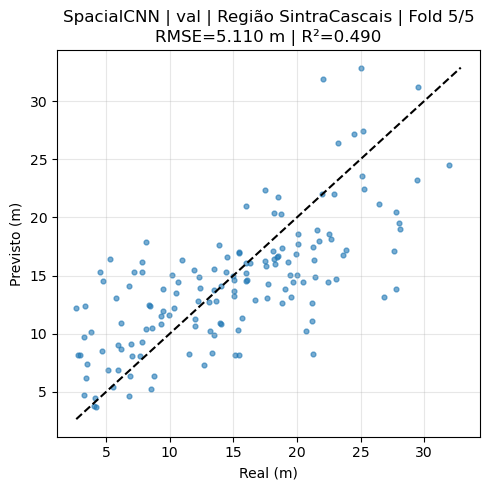

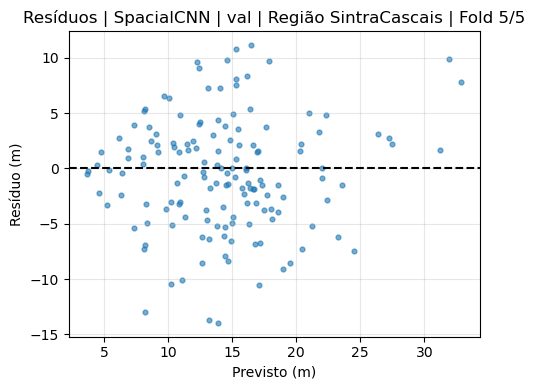


Distribuição das classes de altura por fold — SintraCascais


height_class,0,1,2,3,4
fold,,,,,
1,29,30,30,30,29
2,29,30,30,29,29
3,30,29,29,29,30
4,30,29,29,29,30
5,30,29,29,30,29



#################################################################
 REGIÃO: VPA
#################################################################

Limites das classes de altura:
  Classe 0: 2.54 m até 6.30 m
  Classe 1: 6.30 m até 8.23 m
  Classe 2: 8.23 m até 11.64 m
  Classe 3: 11.64 m até 16.11 m
  Classe 4: 16.11 m até 38.18 m

 Região VPA | Fold 1/5
Treino: 428 amostras
Validação: 107 amostras
Regiões treino: ['VPA']
Regiões validação: ['VPA']
Normalização concluída | média_treino≈0.00000 | std_treino≈1.00000

y_train: média=11.397 m | std=6.072 m | min=2.54 m | max=38.18 m
y_val:   média=11.365 m | std=6.241 m | min=2.80 m | max=33.47 m

Arquitetura: SpacialCNN
Parâmetros totais: 1,298,049 | treináveis: 1,298,049

────────────────────────────────────────────────────────────────────────────────────────
 Época    MSE_tr   MSE_val   RMSE_val   %RMSE      MAE      R²         LR   s/ep     ETA
────────────────────────────────────────────────────────────────────────────────────────
   

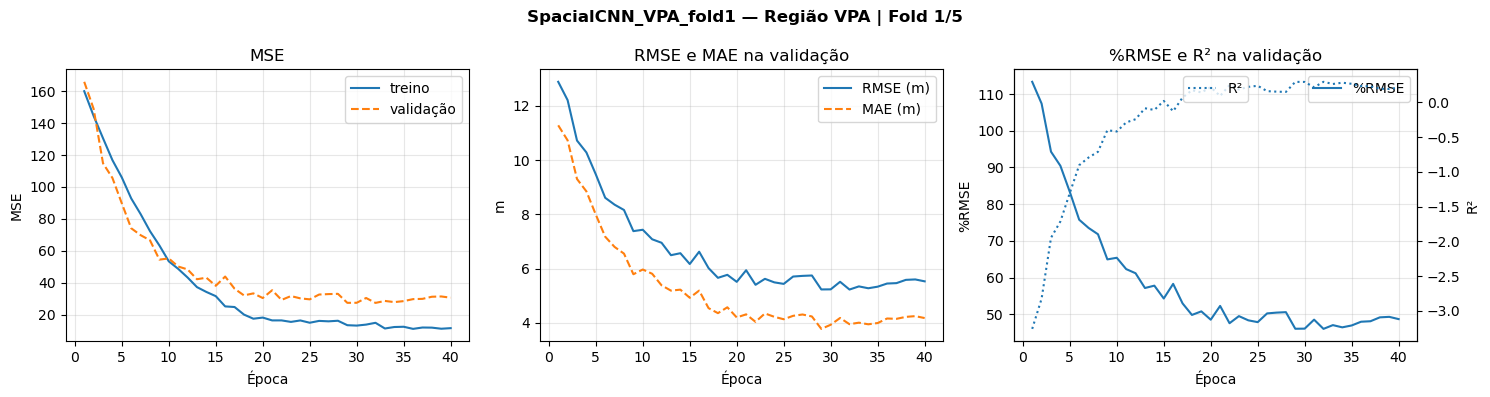

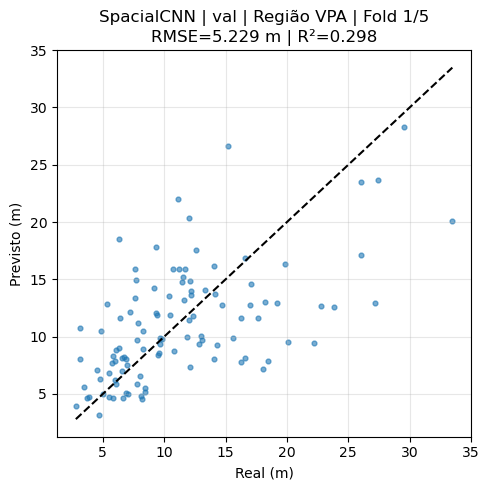

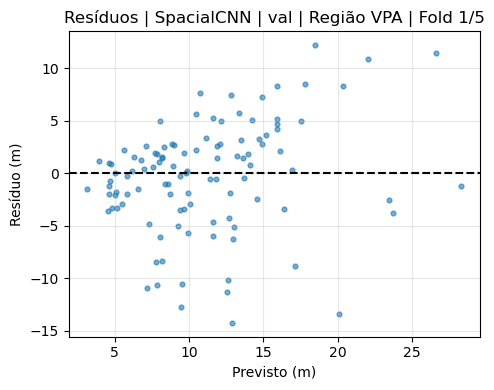


 Região VPA | Fold 2/5
Treino: 428 amostras
Validação: 107 amostras
Regiões treino: ['VPA']
Regiões validação: ['VPA']
Normalização concluída | média_treino≈0.00000 | std_treino≈1.00000

y_train: média=11.354 m | std=6.155 m | min=2.54 m | max=38.18 m
y_val:   média=11.539 m | std=5.900 m | min=2.87 m | max=29.40 m

Arquitetura: SpacialCNN
Parâmetros totais: 1,298,049 | treináveis: 1,298,049

────────────────────────────────────────────────────────────────────────────────────────
 Época    MSE_tr   MSE_val   RMSE_val   %RMSE      MAE      R²         LR   s/ep     ETA
────────────────────────────────────────────────────────────────────────────────────────
     1  160.2543  166.0948    12.888m  111.7%  11.472m  -3.771   3.00e-04   0.3s     11s ⭐
     2  143.0399  153.4720    12.388m  107.4%  11.103m  -3.408   3.00e-04   0.3s     11s ⭐
     3  128.5650  123.6923    11.122m   96.4%   9.971m  -2.553   3.00e-04   0.3s     10s ⭐
     4  116.3214  101.3588    10.068m   87.2%   9.026m  -1.911 

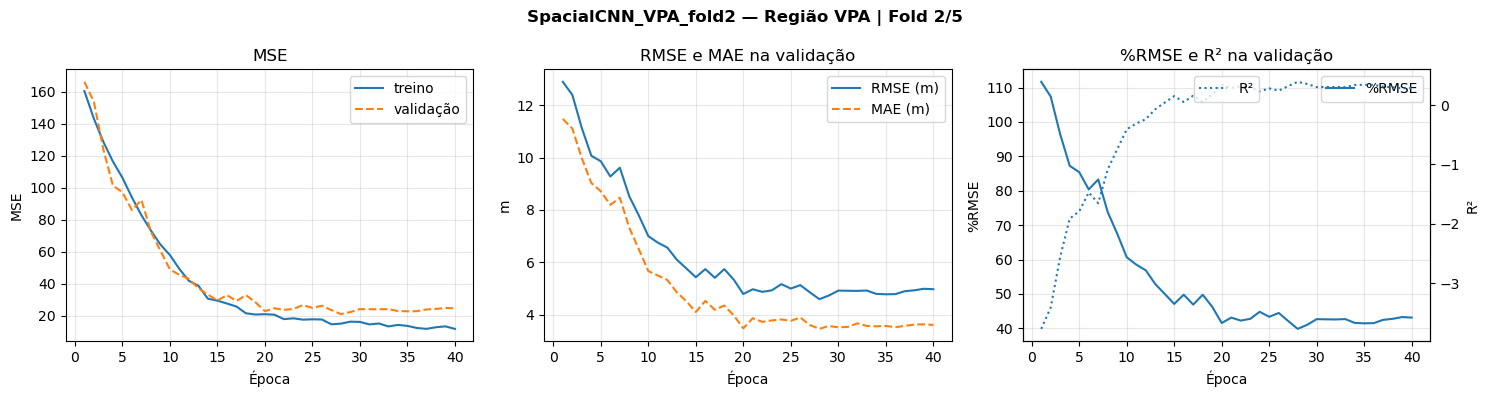

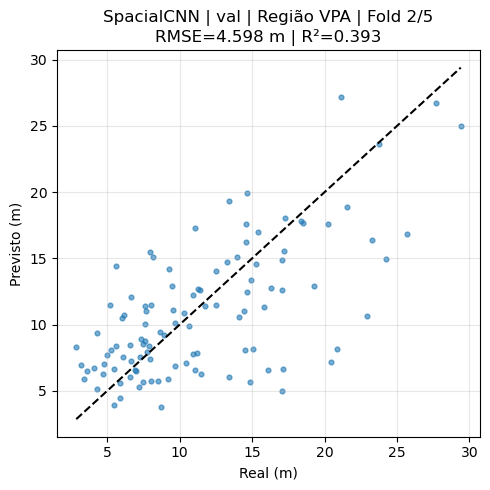

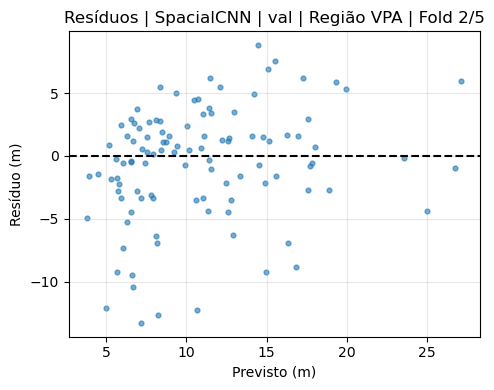


 Região VPA | Fold 3/5
Treino: 428 amostras
Validação: 107 amostras
Regiões treino: ['VPA']
Regiões validação: ['VPA']
Normalização concluída | média_treino≈0.00000 | std_treino≈1.00000

y_train: média=11.478 m | std=6.204 m | min=2.54 m | max=38.18 m
y_val:   média=11.042 m | std=5.683 m | min=2.87 m | max=34.25 m

Arquitetura: SpacialCNN
Parâmetros totais: 1,298,049 | treináveis: 1,298,049

────────────────────────────────────────────────────────────────────────────────────────
 Época    MSE_tr   MSE_val   RMSE_val   %RMSE      MAE      R²         LR   s/ep     ETA
────────────────────────────────────────────────────────────────────────────────────────
     1  163.1906  152.5529    12.351m  111.9%  10.975m  -3.724   3.00e-04   0.3s     11s ⭐
     2  146.0451  143.7110    11.988m  108.6%  10.699m  -3.450   3.00e-04   0.3s     11s ⭐
     3  132.4697  127.1277    11.275m  102.1%  10.064m  -2.937   3.00e-04   0.3s     10s ⭐
     4  119.5296  110.3349    10.504m   95.1%   9.264m  -2.417 

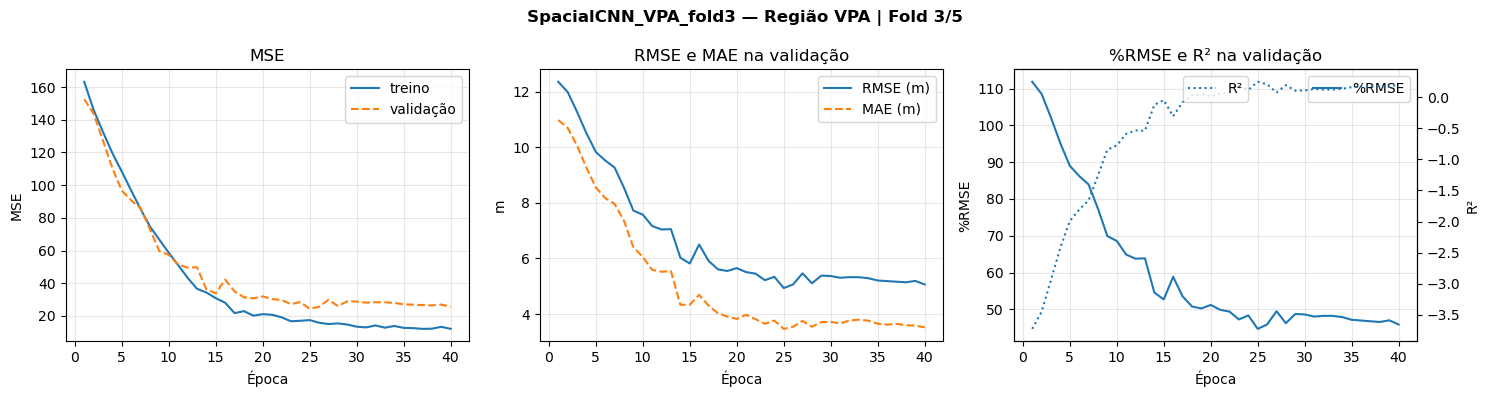

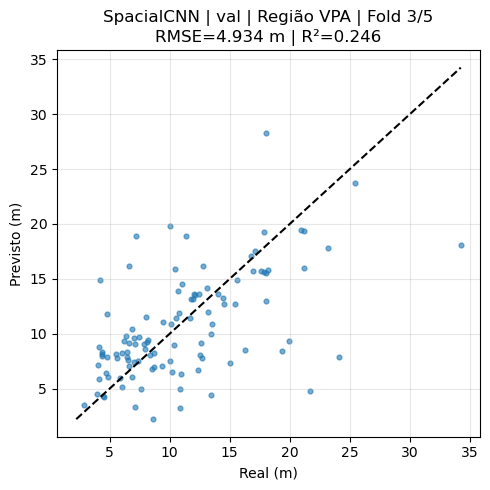

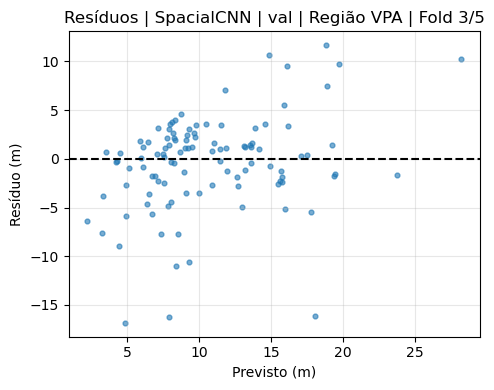


 Região VPA | Fold 4/5
Treino: 428 amostras
Validação: 107 amostras
Regiões treino: ['VPA']
Regiões validação: ['VPA']
Normalização concluída | média_treino≈0.00000 | std_treino≈1.00000

y_train: média=11.325 m | std=5.927 m | min=2.80 m | max=34.25 m
y_val:   média=11.653 m | std=6.767 m | min=2.54 m | max=38.18 m

Arquitetura: SpacialCNN
Parâmetros totais: 1,298,049 | treináveis: 1,298,049

────────────────────────────────────────────────────────────────────────────────────────
 Época    MSE_tr   MSE_val   RMSE_val   %RMSE      MAE      R²         LR   s/ep     ETA
────────────────────────────────────────────────────────────────────────────────────────
     1  156.1256  179.8099    13.409m  115.1%  11.592m  -2.927   3.00e-04   0.3s     11s ⭐
     2  139.9138  171.6084    13.100m  112.4%  11.379m  -2.748   3.00e-04   0.3s     11s ⭐
     3  126.8767  153.5009    12.390m  106.3%  10.766m  -2.352   3.00e-04   0.3s     10s ⭐
     4  113.9236  129.9428    11.399m   97.8%   9.868m  -1.838 

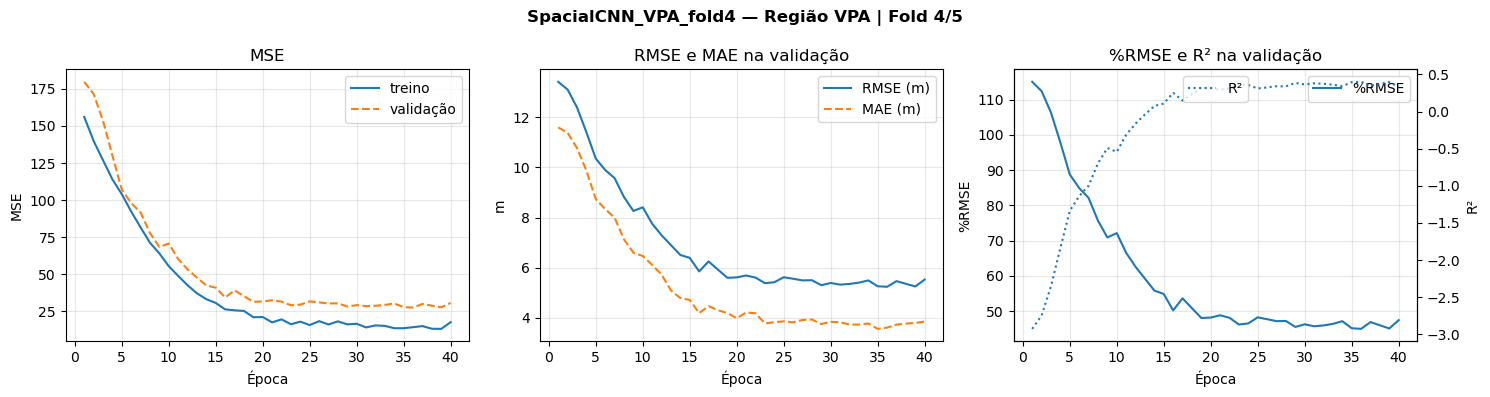

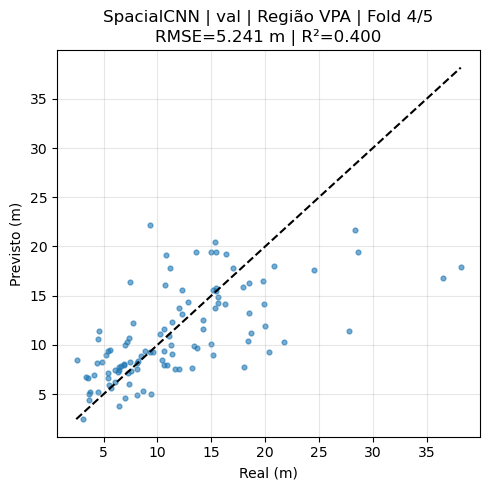

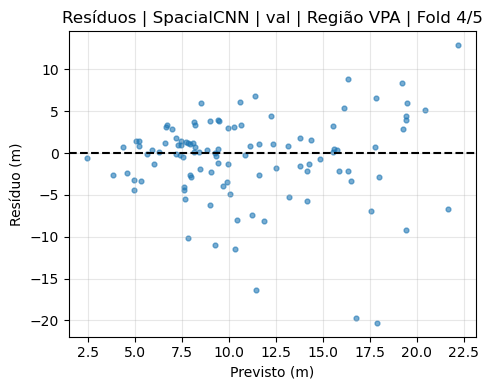


 Região VPA | Fold 5/5
Treino: 428 amostras
Validação: 107 amostras
Regiões treino: ['VPA']
Regiões validação: ['VPA']
Normalização concluída | média_treino≈0.00000 | std_treino≈1.00000

y_train: média=11.400 m | std=6.165 m | min=2.54 m | max=38.18 m
y_val:   média=11.354 m | std=5.860 m | min=2.87 m | max=31.50 m

Arquitetura: SpacialCNN
Parâmetros totais: 1,298,049 | treináveis: 1,298,049

────────────────────────────────────────────────────────────────────────────────────────
 Época    MSE_tr   MSE_val   RMSE_val   %RMSE      MAE      R²         LR   s/ep     ETA
────────────────────────────────────────────────────────────────────────────────────────
     1  161.0278  161.2456    12.698m  111.8%  11.278m  -3.695   3.00e-04   0.3s     11s ⭐
     2  144.0343  146.8671    12.119m  106.7%  10.809m  -3.276   3.00e-04   0.3s     11s ⭐
     3  131.2342  123.3303    11.105m   97.8%   9.875m  -2.591   3.00e-04   0.3s     11s ⭐
     4  117.6017  101.6602    10.083m   88.8%   8.898m  -1.960 

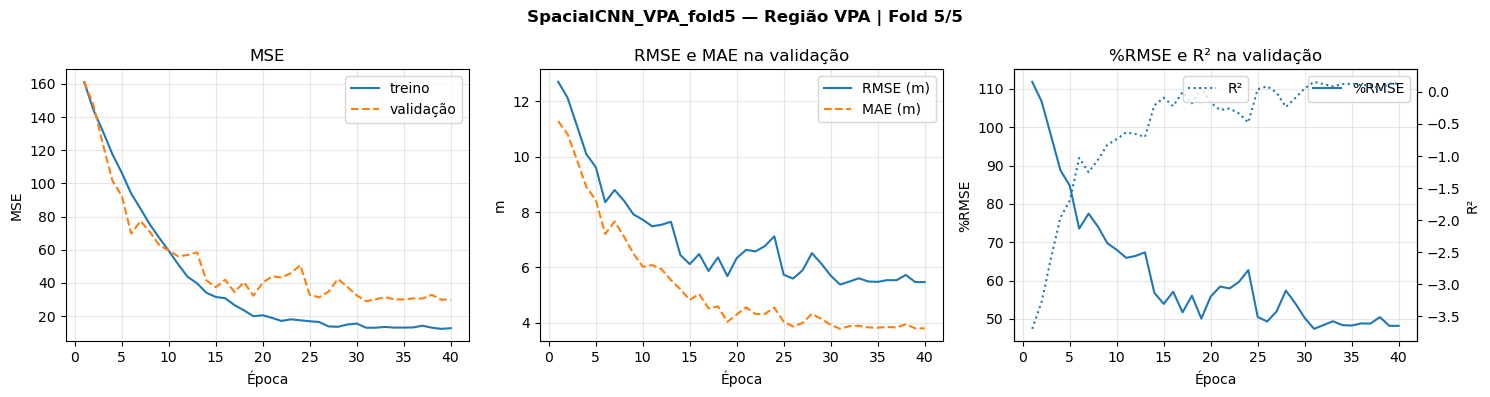

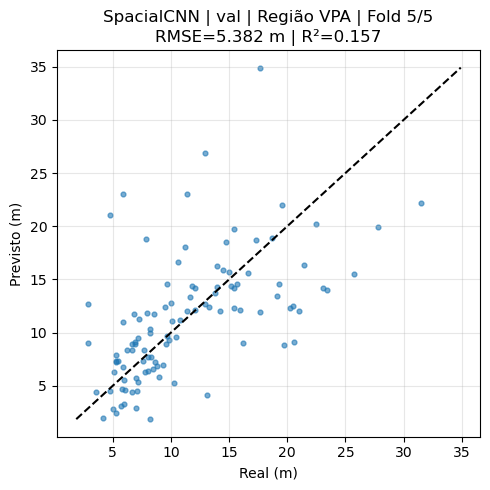

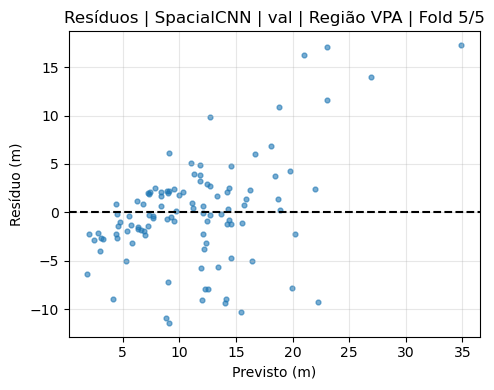


Distribuição das classes de altura por fold — VPA


height_class,0,1,2,3,4
fold,,,,,
1,21,21,22,21,22
2,21,22,21,21,22
3,21,22,21,22,21
4,22,21,21,22,21
5,22,21,22,21,21



=== Resultados por região e fold ===


,model,split,RMSE,%RMSE,MAE,R2,Bias,Covariancia,cv_type,region,fold,n_train,n_val
0,SpacialCNN,val,5.975678,53.300029,4.476280,-0.105664,-1.053768,11.820081,within_region_stratified,Mafra,1,370,93
1,SpacialCNN,val,6.010686,51.218993,4.355216,0.055852,-1.072299,16.574904,within_region_stratified,Mafra,2,370,93
2,SpacialCNN,val,6.405946,53.536397,4.836444,-0.111507,-0.195684,13.646035,within_region_stratified,Mafra,3,370,93
3,SpacialCNN,val,5.426381,46.431952,3.743620,0.118114,-1.566818,18.653605,within_region_stratified,Mafra,4,371,92
4,SpacialCNN,val,5.923997,49.933368,4.618826,0.034941,-1.022420,13.656350,within_region_stratified,Mafra,5,371,92
5,SpacialCNN,val,5.682541,39.020483,4.474889,0.132925,-1.648235,18.556924,within_region_stratified,Monsanto,1,364,91
6,SpacialCNN,val,6.482428,43.287227,4.919312,-0.028780,-0.131475,21.761792,within_region_stratified,Monsanto,2,364,91
7,SpacialCNN,val,4.928657,32.790688,3.744483,0.438905,-0.657989,25.620873,within_region_stratified,Monsanto,3,364,91
8,SpacialCNN,val,4.774404,32.432625,3.824524,0.412180,-0.871241,21.009129,within_region_stratified,Monsanto,4,364,91
9,SpacialCNN,val,5.588677,37.351978,3.999477,0.214786,-0.850364,22.000628,within_region_stratified,Monsanto,5,364,91



=== Resumo por região — média ± desvio padrão das 5 folds ===


RMSE                %RMSE                 MAE            \
                   mean       std       mean       std      mean       std   
region                                                                       
Mafra          5.948538  0.348953  50.884148  2.902975  4.406077  0.411352   
Monsanto       5.491341  0.681707  36.976600  4.536297  4.192537  0.495324   
Pombal         5.423586  0.340733  42.302946  2.627994  4.154985  0.200719   
SerraLousa     5.786562  0.116656  35.328640  0.685318  4.465572  0.047724   
SintraCascais  5.662723  0.314602  36.896101  1.361126  4.291556  0.233764   
VPA            5.076715  0.313491  44.581864  2.854404  3.656205  0.211692   

                     R2                Bias           Covariancia            
                   mean       std      mean       std        mean       std  
region                                                                       
Mafra         -0.001653  0.102318 -0.982198  0.493772   14.870195  2.715484  
Monsanto       0.234003  0.195814 -0.831861  0.545237   21.789869  2.538862  
Pombal         0.195510  0.086424 -0.416078  0.344089   14.828640  3.869644  
SerraLousa     0.471262  0.009977 -0.271700  0.123075   32.636555  4.448296  
SintraCascais  0.501101  0.041236 -0.813321  0.269464   40.438942  9.701255  
VPA            0.298726  0.102553 -0.399830  0.273179   18.539211  1.743942


=== Resumo global simples — média ± desvio padrão de todas as folds ===


RMSE                %RMSE                 MAE            \
                mean       std       mean       std      mean       std   
model                                                                     
SpacialCNN  5.564911  0.454925  41.161716  6.079448  4.194489  0.386018   

                  R2                Bias           Covariancia             
                mean       std      mean       std        mean        std  
model                                                                      
SpacialCNN  0.283158  0.198798 -0.619164  0.431979   23.850569  10.695282


Resultados guardados em: outputs_fch\spacial_cnn\cv_por_regiao_estratificado


In [9]:
# ============================================================
# 9. PIPELINE — CROSS-VALIDATION DENTRO DE CADA REGIÃO
# ============================================================

print("=" * 65)
print(" PIPELINE FCH — SpacialCNN — CV por região")
print("=" * 65)

X_all, y_all, regions_all, point_ids_all = load_all_regions_tifs(
    RAW_BASE_DIR,
    VALIDATION_DIR,
    target_column=TARGET_COLUMN,
)

available_regions = sorted(np.unique(regions_all))
print(f"\nRegiões disponíveis: {available_regions}")

all_results = []
all_histories = {}
all_fold_assignments = []

for region in available_regions:
    print("\n" + "#" * 65)
    print(f" REGIÃO: {region}")
    print("#" * 65)

    region_idx = np.where(regions_all == region)[0]
    X_region = X_all[region_idx]
    y_region = y_all[region_idx]
    point_ids_region = point_ids_all[region_idx]

    height_classes, bin_edges = choose_height_classes_for_cv(
        y_region,
        n_splits=N_SPLITS,
        max_bins=N_HEIGHT_BINS,
        label=f"Região {region}",
    )

    print_height_bins(bin_edges, target_scale=TARGET_SCALE)

    skf = StratifiedKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=SEED,
    )

    fold_ids_region = np.full(len(region_idx), fill_value=-1, dtype=int)

    for fold, (train_local_idx, val_local_idx) in enumerate(
        skf.split(X_region, height_classes),
        start=1,
    ):
        train_idx = region_idx[train_local_idx]
        val_idx = region_idx[val_local_idx]
        fold_ids_region[val_local_idx] = fold

        model_name = f"SpacialCNN_{safe_name(region)}_fold{fold}"
        fold_label = f"Região {region} | Fold {fold}/{N_SPLITS}"

        results_df, history = run_fold(
            X_all=X_all,
            y_all=y_all,
            regions_all=regions_all,
            point_ids_all=point_ids_all,
            train_idx=train_idx,
            val_idx=val_idx,
            model_name=model_name,
            fold_label=fold_label,
            result_extra={
                "cv_type": "within_region_stratified",
                "region": region,
                "fold": fold,
            },
        )

        all_results.append(results_df)
        all_histories[(region, fold)] = history

    assignments_region = pd.DataFrame({
        "region": region,
        "point_id": point_ids_region,
        "y_cm": y_region,
        "y_m": y_region / TARGET_SCALE,
        "height_class": height_classes,
        "fold": fold_ids_region,
    })

    all_fold_assignments.append(assignments_region)

    print(f"\nDistribuição das classes de altura por fold — {region}")
    display(pd.crosstab(assignments_region["fold"], assignments_region["height_class"]))

# ============================================================
# 10. RESUMO FINAL
# ============================================================

final_df = pd.concat(all_results, ignore_index=True)
fold_assignments_df = pd.concat(all_fold_assignments, ignore_index=True)

print("\n=== Resultados por região e fold ===")
display(final_df)

print("\n=== Resumo por região — média ± desvio padrão das 5 folds ===")
summary_by_region = summarize_final_results(final_df, group_cols=["region"])

print("\n=== Resumo global simples — média ± desvio padrão de todas as folds ===")
summary_global = summarize_final_results(final_df, group_cols=["model"])

final_df.to_csv(OUTPUT_DIR / "resultados_cv_por_regiao_estratificado.csv", index=False)
fold_assignments_df.to_csv(OUTPUT_DIR / "fold_assignments_cv_por_regiao.csv", index=False)
summary_by_region.to_csv(OUTPUT_DIR / "resumo_cv_por_regiao.csv")
summary_global.to_csv(OUTPUT_DIR / "resumo_cv_por_regiao_global.csv")

print(f"\nResultados guardados em: {OUTPUT_DIR}")
